# Setup

In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery
library(data.table )

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

install.packages("pROC")
library(pROC)

install.packages("pheatmap")
library(pheatmap)


## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}



[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is

## Set up lists

In [2]:
diseases0<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")


sdoh_var <-c('Own Home', 'Health Literacy', 'Housing Quality', 'Housing Instability',
             'Food Insecurity', 'Walkability', 'Loneliness', 'Crime', 'Physical Disorder', 'Social Disorder',
             'Everyday Discrimination', 'Medical Discrimination', 'Social Cohesion', 'Stress', 
             'Social Support', 'Spiritual Experiences', 'Health Coverage', 'Healthcare Utilization',
             'Delayed Care', 'Can\'t afford care', 'Worried Pay', 'Respect'
)

## Load and merge data

In [3]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

# Imputed individual-level SDoH data from Social Determinants of Health Measurement Models V8 community workspace
name_of_file_in_bucket <- 'imputed_individual_level_SDOH.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/imputed_individual_level_SDOH.csv ."), intern=T)
sdoh_data <- read_csv(name_of_file_in_bucket) |> select(c("person_id", sdoh_var))

#MERGE
demo_sdoh<-dplyr::inner_join(demo, sdoh_data, by = "person_id")

#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#MERGE
all_data_0<-dplyr::inner_join(demo_sdoh, PRS, by = "person_id")

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)


Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 54313 Columns: 37
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): SexGender
dbl (30): person_id, race_unknown, record_depth, visit_frequency, age, Educa...
lgl  (6): Black, Mid, Multiple, White, His, AANHPI

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Using an external vector in selections was deprecated in tidyselect 1.1.0.
ℹ Please use `all_of()` or `any_of()` instead.
  # Was:
  data %>% select(sdoh_var)

  # Now:
  data %>% select(all_of(sdoh_var))

See <https://tidyselect.r-lib.org/reference/faq-external-vector.html>.”
Rows: 135557 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adju...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Spe

character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [4]:
#MERGE
merged_data<-dplyr::inner_join(all_data_0, case_control, by = "person_id")
colnames(merged_data)

merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

[1] "person_id"                  "date_of_birth"             
 [3] "AIAN"                       "Asian"                     
 [5] "Black"                      "Mid"                       
 [7] "Multiple"                   "PI"                        
 [9] "White"                      "His"                       
[11] "race_unknown"               "SexGender"                 
[13] "age_today"                  "ancestry_pred"             
[15] "PC_1"                       "PC_2"                      
[17] "PC_3"                       "PC_4"                      
[19] "PC_5"                       "PC_6"                      
[21] "PC_7"                       "PC_8"                      
[23] "PC_9"                       "PC_10"                     
[25] "PC_11"                      "PC_12"                     
[27] "PC_13"                      "PC_14"                     
[29] "PC_15"                      "PC_16"                     
[31] "number_living"              "where_born"                
[33] "military"                   "healthcare"                
[35] "disabled"                   "sexual_orientation"        
[37] "LGBTQIA"                    "basics_survey_datetime"    
[39] "income_grouped"             "min_date"                  
[41] "max_date"                   "ehr_length"                
[43] "relative_health"            "record_depth"              
[45] "visit_frequency"            "age"                       
[47] "record_depth_winsorized"    "visit_frequency_winsorized"
[49] "age2"                       "Own Home"                  
[51] "Health Literacy"            "Housing Quality"           
[53] "Housing Instability"        "Food Insecurity"           
[55] "Walkability"                "Loneliness"                
[57] "Crime"                      "Physical Disorder"         
[59] "Social Disorder"            "Everyday Discrimination"   
[61] "Medical Discrimination"     "Social Cohesion"           
[63] "Stress"                     "Social Support"            
[65] "Spiritual Experiences"      "Health Coverage"           
[67] "Healthcare Utilization"     "Delayed Care"              
[69] "Can't afford care"          "Worried Pay"               
[71] "Respect"                    "Asthma_adjusted_score"     
[73] "Afib_adjusted_score"        "BreastC_adjusted_score"    
[75] "CKD_adjusted_score"         "CHD_adjusted_score"        
[77] "ProstateC_adjusted_score"   "t1d_adjusted_score"        
[79] "t2d_adjusted_score"         "Asthma"                    
[81] "Afib"                       "BreastC"                   
[83] "CKD"                        "CHD"                       
[85] "HyperC"                     "ProstateC"                 
[87] "t2d"                        "t1d"

In [5]:
#Check case counts
sapply(merged_data[, diseases0], function(x) table(x))
       
#Subset to diseases with more than 3,000 cases
diseases <- setdiff(diseases0, c("BreastC", "ProstateC", "t1d"))
diseases

,Asthma,Afib,BreastC,CKD,CHD,ProstateC,t2d,t1d
0,7736,7627,27223,13814,39239,3658,17512,17512
1,5558,4043,2806,3800,6277,1915,7579,625


[1] "Asthma" "Afib"   "CKD"    "CHD"    "t2d"

In [6]:
dim(merged_data)

[1] 47442    91

## Set up maps

In [7]:
disease_name_mapping <- c(
  "Asthma" = "Asthma",
    "Afib" = "Afib",
    "CKD" = "CKD", 
    "CHD" = "CHD",
  "t2d" = "T2D"
)

disease_order <- c( "Afib", 
                   "T2D", "CKD", "CHD",
                  "Asthma")


## -----------------------------
## Bonferroni correction
## -----------------------------
n_disease <- length(diseases)
n_sdoh    <- length(sdoh_var)
alpha_bonf <- 0.05 / (n_disease * n_sdoh)

alpha_bonf 

[1] 0.0004545455

## Prepare SDoH variables

In [8]:
#Flip and z-score
# variables to reverse-code
to_flip <- c(
  "Health Coverage", "Health Literacy", "Healthcare Utilization",
  "Housing Quality", "Own Home", "Respect", "Social Cohesion",
  "Social Support", "Spiritual Experiences", "Walkability"
)

# -------------------------------------------------
# 1. Flip binary coding: 1 -> 0, 0 -> 1
# -------------------------------------------------
merged_data[to_flip] <- lapply(
  merged_data[to_flip],
  function(x) ifelse(is.na(x), NA, 1 - x)
)

# -------------------------------------------------
# 2. Rename variables after flipping
# -------------------------------------------------
new_names <- c(
  "No Health Coverage",
  "Low Health Literacy",
  "Low Healthcare Utilization",
  "Low Housing Quality",
  "No Own Home",
  "Low Respect",
  "Low Social Cohesion",
  "Low Social Support",
  "Low Spiritual Experiences",
  "Low Walkability"
)

sdoh_var <-c('No Own Home', 'Low Health Literacy', 'Low Housing Quality', 'Housing Instability',
             'Food Insecurity', 'Low Walkability', 'Loneliness', 'Crime', 'Physical Disorder', 'Social Disorder',
             'Everyday Discrimination', 'Medical Discrimination', 'Low Social Cohesion', 'Stress', 
             'Low Social Support', 'Low Spiritual Experiences', 'No Health Coverage', 'Low Healthcare Utilization',
             'Delayed Care', 'Can\'t afford care', 'Worried Pay', 'Low Respect'
)

names(merged_data)[match(to_flip, names(merged_data))] <- new_names



## Fix binary variables (imputation gave some inbetween values will assign to closest value here)

In [9]:
binary_vars <- c("Food Insecurity", "Can't afford care", "Housing Instability", "Low Health Literacy", 
                "Delayed Care", "Low Housing Quality", "No Health Coverage", "No Own Home")
sapply(merged_data[, binary_vars], function(x) table(x))
       
merged_data[, binary_vars] <- lapply(
  merged_data[, binary_vars],
  function(x) as.numeric(
    ifelse(is.na(x), NA, ifelse(x < 0.5, 0, 1))
  )
)
       
sapply(merged_data[, binary_vars], function(x) table(x))

$`Food Insecurity`
x
    0   0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8   0.9     1 
43154    27    15    11     7     3     4     3     5     4  4209 

$`Can't afford care`
x
    0   0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8   0.9     1 
28159   779   808   618   450   284   225   148   140   108 15723 

$`Housing Instability`
x
    0   0.3     1 
38383     1  9058 

$`Low Health Literacy`
x
    0   0.1   0.2   0.3   0.4   0.5   0.6   0.8     1 
37105     8    10     4     9     2     3     2 10299 

$`Delayed Care`
x
    0   0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8   0.9     1 
29645  1353   920   586   455   270   212   165   122   114 13600 

$`Low Housing Quality`
x
    0   0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8   0.9     1 
37344   608   366   189    98    49    33    15    14     2  8724 

$`No Health Coverage`
x
    0   0.2   0.3   0.4   0.7     1 
42635     5     1     2     1  4798 

$`No Own Home`
x
    0   0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8   0

,Food Insecurity,Can't afford care,Housing Instability,Low Health Literacy,Delayed Care,Low Housing Quality,No Health Coverage,No Own Home
0,43214,30814,38384,37136,32959,38605,42643,34753
1,4228,16628,9058,10306,14483,8837,4799,12689


In [10]:
continious_vars <- setdiff(sdoh_var, binary_vars)

merged_data[continious_vars] <- lapply(
  merged_data[continious_vars],
  function(x) as.numeric(scale(ifelse(is.na(x), NA, x)))
)

## Plot distributions

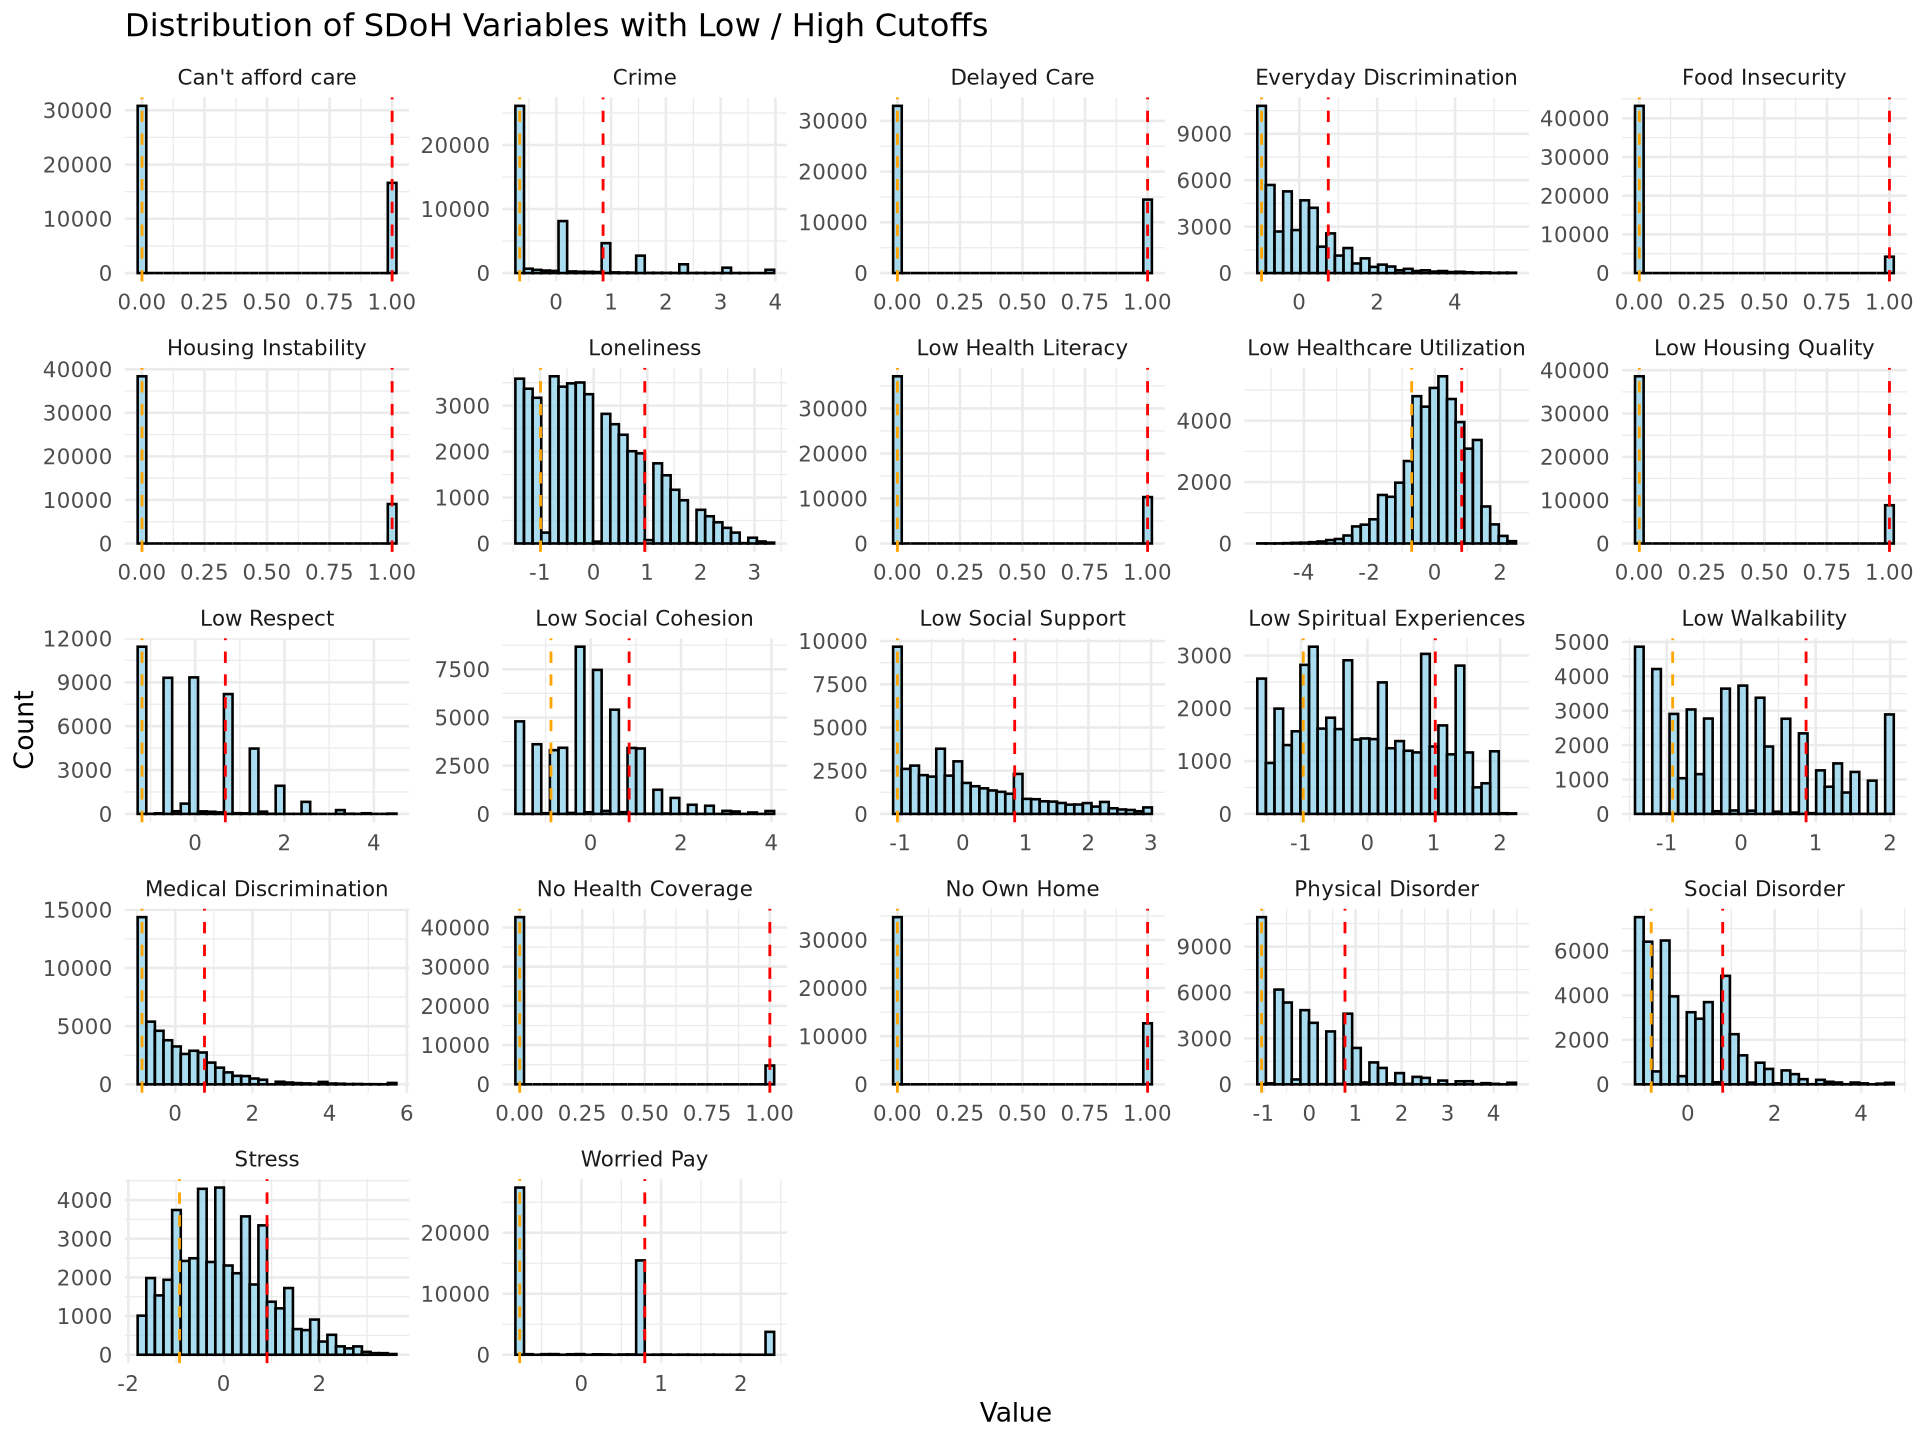

In [11]:
options(
    repr.plot.width  = 16,
    repr.plot.height = 12
  )

# --- Reshape to long format ---
long_data <- merged_data %>%
  dplyr::select(all_of(sdoh_var)) %>%
  tidyr::pivot_longer(
    cols = everything(),
    names_to = "domain",
    values_to = "value"
  )

# --- Calculate cutoffs (binary handled separately) ---
quantiles <- long_data %>%
  dplyr::group_by(domain) %>%
  dplyr::summarise(
    q1 = if (dplyr::n_distinct(stats::na.omit(value)) <= 2) {
      min(value, na.rm = TRUE)   # usually 0
    } else {
      as.numeric(stats::quantile(value, 0.20, na.rm = TRUE))
    },

    q5 = if (dplyr::n_distinct(stats::na.omit(value)) <= 2) {
      max(value, na.rm = TRUE)   # usually 1
    } else {
      as.numeric(stats::quantile(value, 0.80, na.rm = TRUE))
    },

    .groups = "drop"
  )

# --- Merge back ---
plot_data <- long_data %>%
  dplyr::left_join(quantiles, by = "domain")

# --- Plot ---
ggplot(plot_data, aes(x = value)) +
  geom_histogram(
    bins = 30,
    fill = "skyblue",
    color = "black",
    alpha = 0.7
  ) +
  geom_vline(
    aes(xintercept = q1),
    color = "orange",
    linetype = "dashed",
    linewidth = 0.8
  ) +
  geom_vline(
    aes(xintercept = q5),
    color = "red",
    linetype = "dashed",
    linewidth = 0.8
  ) +
  facet_wrap(~domain, scales = "free") +
  labs(
    x = "Value",
    y = "Count",
    title = "Distribution of SDoH Variables with Low / High Cutoffs"
  ) +
  theme_minimal(base_size = 16)



In [12]:
long_data |>
  dplyr::group_by(domain) |>
  dplyr::summarise(
    mean   = round(mean(value, na.rm = TRUE), 3),
    median = round(median(value, na.rm = TRUE), 3),
    sd     = round(sd(value, na.rm = TRUE), 3),
    min    = round(min(value, na.rm = TRUE), 3),
    max    = round(max(value, na.rm = TRUE), 3),

    q1 = if (dplyr::n_distinct(stats::na.omit(value)) <= 2) {
      min(value, na.rm = TRUE)
    } else {
      round(as.numeric(stats::quantile(value, 0.20, na.rm = TRUE)), 3)
    },

    q5 = if (dplyr::n_distinct(stats::na.omit(value)) <= 2) {
      max(value, na.rm = TRUE)
    } else {
      round(as.numeric(stats::quantile(value, 0.80, na.rm = TRUE)), 3)
    },

    n_q1 = if (dplyr::n_distinct(stats::na.omit(value)) <= 2) {
      sum(value == 0, na.rm = TRUE)
    } else {
      sum(value <= stats::quantile(value, 0.20, na.rm = TRUE), na.rm = TRUE)
    },

    n_q5 = if (dplyr::n_distinct(stats::na.omit(value)) <= 2) {
      sum(value == 1, na.rm = TRUE)
    } else {
      sum(value >= stats::quantile(value, 0.80, na.rm = TRUE), na.rm = TRUE)
    },

    n_total = sum(!is.na(value)),
    .groups = "drop"
  )

domain,mean,median,sd,min,max,q1,q5,n_q1,n_q5,n_total
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<int>
Can't afford care,0.350,0.000,0.477,0.000,1.000,0.000,1.000,30814,16628,47442
Crime,0.000,-0.669,1.000,-0.669,3.897,-0.669,0.853,25657,10499,47442
Delayed Care,0.305,0.000,0.461,0.000,1.000,0.000,1.000,32959,14483,47442
Everyday Discrimination,0.000,-0.255,1.000,-0.969,5.455,-0.969,0.744,10773,9559,47442
Food Insecurity,0.089,0.000,0.285,0.000,1.000,0.000,1.000,43214,4228,47442
Housing Instability,0.191,0.000,0.393,0.000,1.000,0.000,1.000,38384,9058,47442
Loneliness,0.000,-0.214,1.000,-1.381,3.287,-0.992,0.953,10129,9854,47442
Low Health Literacy,0.217,0.000,0.412,0.000,1.000,0.000,1.000,37136,10306,47442
Low Healthcare Utilization,0.000,0.061,1.000,-5.292,2.355,-0.704,0.825,10358,10008,47442


# Regressions

## Make functions

In [13]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "age2", "record_depth", "visit_frequency")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

fit_by_quantiles <- function(formula, disease, sdoh_var, data, n_quantiles = 5) {

  # --------------------------------------------------
  # 1. Filter missing
  # --------------------------------------------------
  data <- data %>%
    filter(!is.na(.data[[sdoh_var]]))

  # --------------------------------------------------
  # 2. Disease-specific filters
  # --------------------------------------------------
  if (disease %in% c("CKD")) data <- data %>% filter(SexGenderSGM == 0)

  # --------------------------------------------------
  # 3. Detect binary vs continuous
  # --------------------------------------------------
  is_binary <- dplyr::n_distinct(na.omit(data[[sdoh_var]])) <= 2

  # --------------------------------------------------
  # 4. Create groups
  # --------------------------------------------------
  if (is_binary) {
    data <- data %>%
      mutate(quantile_group = case_when(
          .data[[sdoh_var]] == 0 ~ 1,
          .data[[sdoh_var]] == 1 ~ 5,
          TRUE ~ NA_real_))
  } else {
    data <- data %>%
      mutate(quantile_group = ntile(.data[[sdoh_var]], n_quantiles))
  }

  # --------------------------------------------------
  # 5. Fit models by group
  # --------------------------------------------------
  results <- data %>%
    group_by(quantile_group) %>%
    group_map(~ {

      model <- glm(formula, data = .x, family = binomial(link = "logit"))

      preds <- predict(model, type = "response")
      actuals <- model$y

      if (length(unique(actuals)) > 1) {
        roc_obj <- roc(actuals, preds, quiet = TRUE)
        auc <- as.numeric(auc(roc_obj))
        auc_ci <- as.numeric(ci.auc(roc_obj))
      } else {
        auc <- NA_real_
        auc_ci <- c(NA_real_, NA_real_, NA_real_)
      }

      tidy(model) %>%
        mutate(
          Disease = disease,
          Quantile_Group = .y$quantile_group,
          SDoH_Variable = sdoh_var,
          AUC = auc,
          AUC_CI_Lower = auc_ci[1],
          AUC_CI_Upper = auc_ci[3],
          OR = exp(estimate),
          OR_Lower = exp(estimate - 1.96 * std.error),
          OR_Upper = exp(estimate + 1.96 * std.error)
        )
    }) %>%
    bind_rows()

  return(results)
}

## Run

In [14]:
# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)


#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("adjusted_score", results$term), ] #Only interested in PRS term

#Map names for display
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results_no_adj <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

Warning message:
“There were 16 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, merged_data))`.
ℹ In row 3.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 15 remaining warnings.”


# Graph PRS Odds Ratios 

## Prepare data

In [15]:
prepare_sdoh_prs_forest_data <- function(
  results
) {

  ## -----------------------------
  ## Wide table for Q5 vs Q1 contrast
  ## -----------------------------
  wide <- results %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, estimate,
      OR, std.error, OR_Upper, OR_Lower
    ) %>%
    tidyr::pivot_wider(
      names_from  = Quantile_Group,
      values_from = c(estimate, OR, std.error, OR_Upper, OR_Lower),
      names_sep   = "_"
    )

  ## -----------------------------
  ## z-test + significance flags
  ## -----------------------------
  ann_df <- wide %>%
  mutate(
    var_OR_5 = (OR_5 * std.error_5)^2,
    var_OR_1 = (OR_1 * std.error_1)^2,
    z  = (OR_5 - OR_1) / sqrt(var_OR_5 + var_OR_1),
    z_test_p_value = 2 * pnorm(-abs(z)),
    bonf_sig = z_test_p_value < alpha_bonf,
    fdr_sig      = p.adjust(z_test_p_value, method = "BH") < 0.05,
    sig = z_test_p_value < 0.05
  )

  ## -----------------------------
  ## Join back to long dataframe
  ## -----------------------------
  estimate_q15_out <- results %>%
    left_join(
      ann_df %>%
        select(Disease, SDoH_Variable, z, z_test_p_value, bonf_sig, fdr_sig, sig),
      by = c("Disease", "SDoH_Variable")
    )

  estimate_q15_out
}

estimate_q15_out_no_adj <- prepare_sdoh_prs_forest_data(results_no_adj)

#Save table
write_excel_csv(estimate_q15_out_no_adj, file.path(output_dir, "OR_stratified_analyses_sdoh.csv"))

## Plot

Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”
`height` was translated to `width`.
Warning message:
“Removed 110 rows containing missing values or values outside the scale range
(`geom_vline()`).”


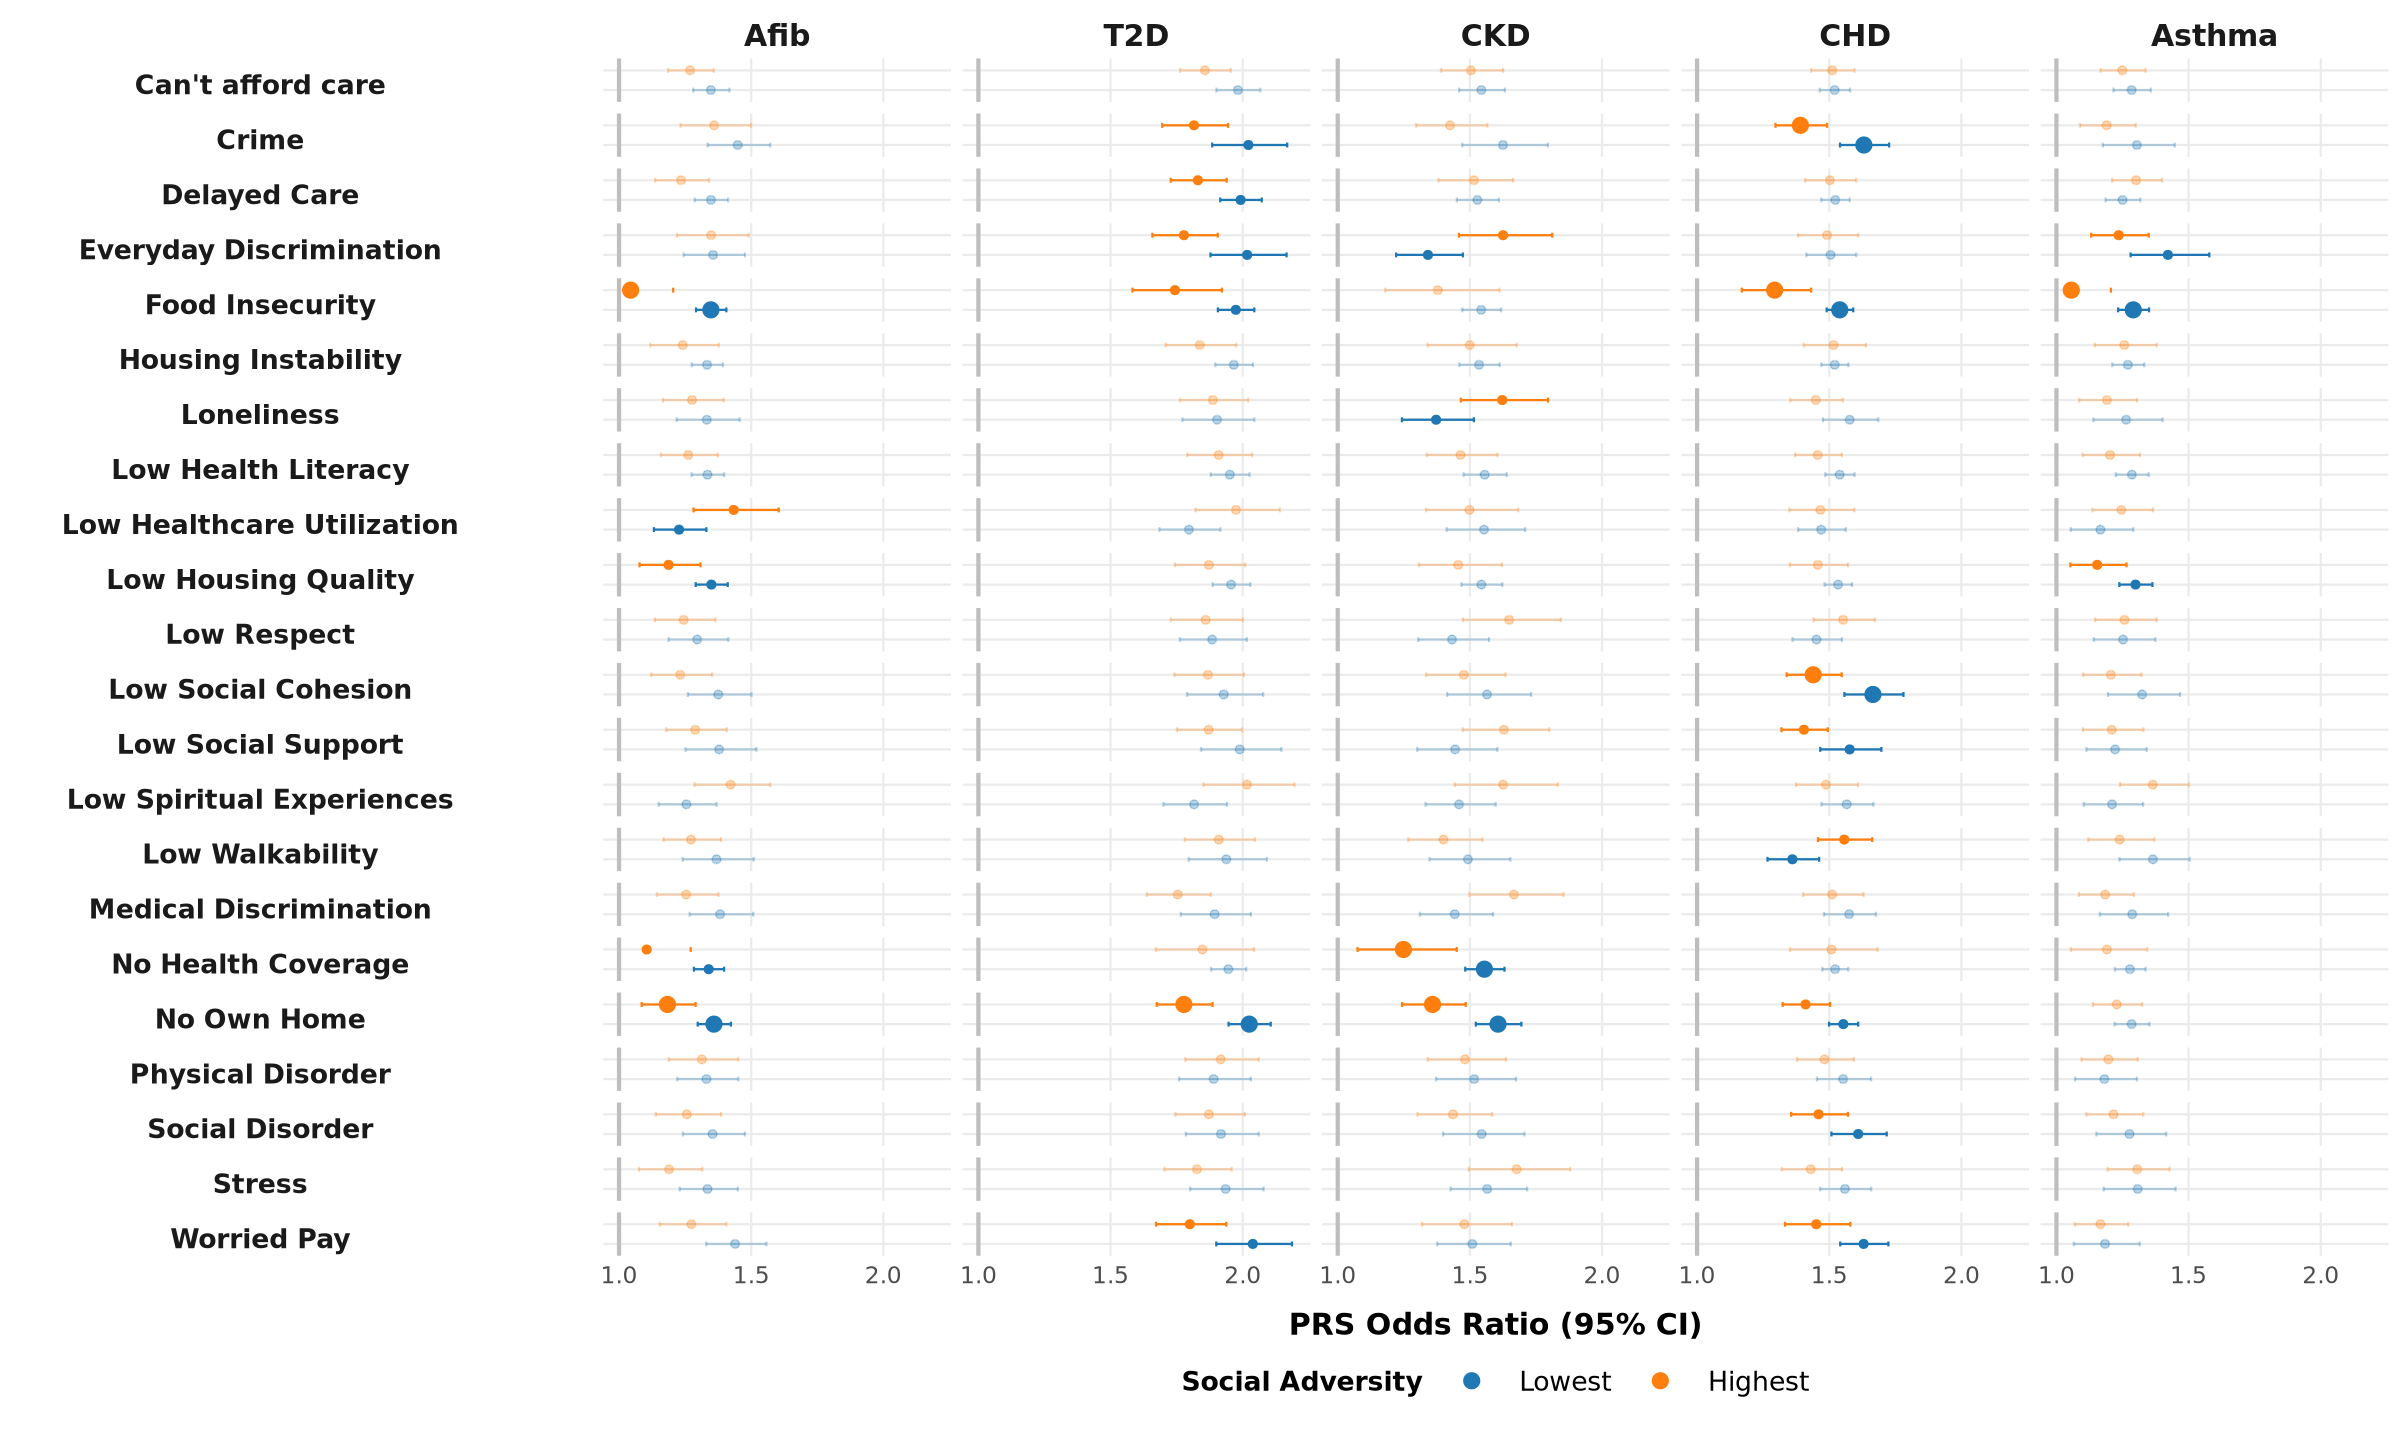

In [16]:
plot_sdoh_prs_forest <- function(
  df,
  width  = 20,
  height = 12,
  x_label = "PRS Odds Ratio (95% CI)"
) {

  p <- ggplot(
    df,
    aes(x = OR, y = Quantile, color = Quantile)
  ) +

    # Error bars (fade if not significant)
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper,
        alpha = sig
      ),
      height = 0.25,
      show.legend = FALSE
    ) +

    # Reference lines
    geom_vline(xintercept = 0, color = "grey", linewidth = 1.2) +
    geom_vline(xintercept = 1, color = "grey", linewidth = 1.2) +

    # Points
    geom_point(
      aes(
        alpha = sig,
        size  = fdr_sig
      )
    ) +

    scale_x_continuous(
      name   = x_label,
      breaks = c(1, 1.5, 2),
      limits = c(
        1,
        max(1, max(df$OR_Upper, na.rm = TRUE))
      )
    ) +

    scale_color_manual(
      values = c(Q1 = "#1f77b4", Q5 = "#ff7f0e"),
      labels = c(
        Q1 = "Lowest",
        Q5 = "Highest"
      )
    ) +

    scale_size_manual(
      values = c(`FALSE` = 2, `TRUE` = 4),
      guide  = "none"
    ) +

    scale_alpha_manual(
      values = c(`FALSE` = 0.3, `TRUE` = 1),
      guide  = "none"
    ) +

    labs(
      y     = "Quantile",
      color = "Social Adversity"
    ) +

    facet_grid(
      rows   = vars(SDoH_Variable),
      cols   = vars(Disease),
      scales = "free_y",
      switch = "y"
    ) +

    theme_minimal(base_size = 14) +
    theme(
      axis.text.x        = element_text(size = 14, margin = margin(t = 4)),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 18, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_blank(),
      strip.text.y.left  = element_text(size = 16, angle = 0, face = "bold", vjust = .5, 
                                       margin = margin(t = 5, r = 30, l =30)),
      strip.placement    = "outside",
      strip.switch.pad.grid = unit(2, "cm"),
      strip.text.x       = element_text(size = 18, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 16),
      legend.title       = element_text(size = 16, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) +

    guides(
      color = guide_legend(override.aes = list(size = 4))
    )

  options(
    repr.plot.width  = width,
    repr.plot.height = height
  )

  p
}

p_forest <- plot_sdoh_prs_forest(estimate_q15_out_no_adj)
print(p_forest)

# Redo Controlling for PCs

In [17]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency", paste0("PC_", 1:16))
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("adjusted_score", results$term), ] #Only interested in PRS term

#Map names for display
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results_adj_PCs <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

Warning message:
“There were 16 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, merged_data))`.
ℹ In row 3.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 15 remaining warnings.”


`height` was translated to `width`.
Warning message:
“Removed 110 rows containing missing values or values outside the scale range
(`geom_vline()`).”


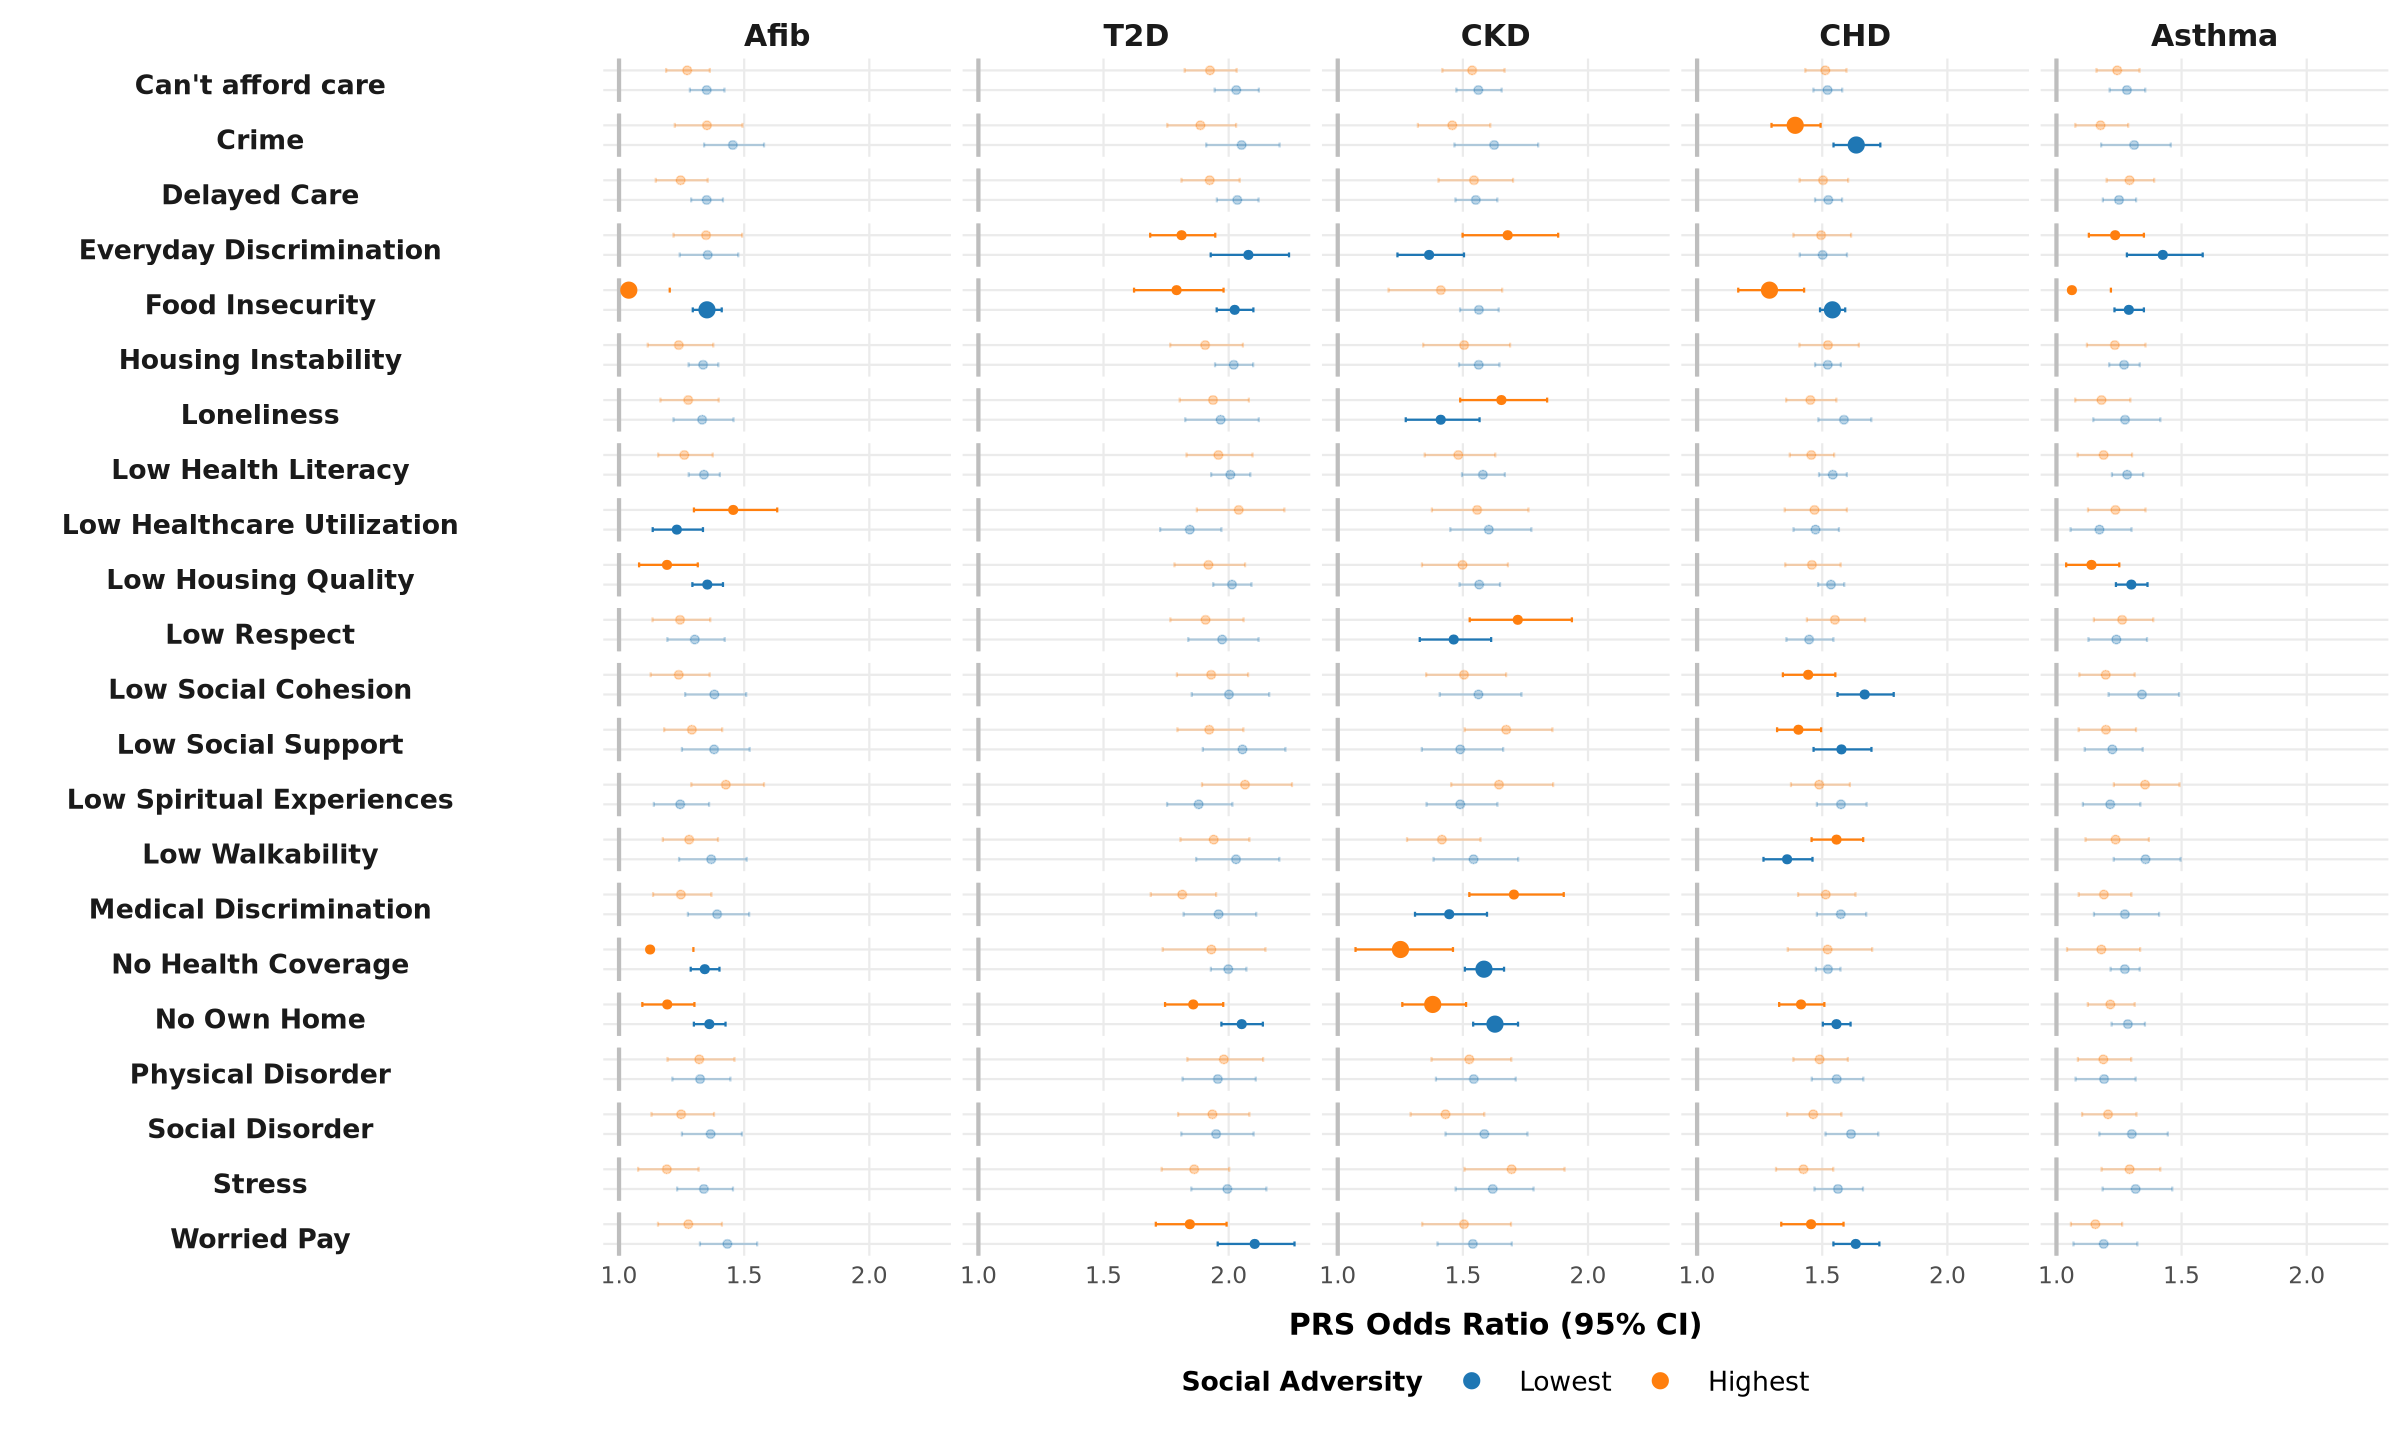

In [18]:
estimate_q15_out_adj_PCs <- prepare_sdoh_prs_forest_data(results_adj_PCs)

#Save table
write_excel_csv(estimate_q15_out_adj_PCs, file.path(output_dir, "OR_stratified_analyses_sdoh_controlling_PCs.csv"))

p_forest <- plot_sdoh_prs_forest(estimate_q15_out_adj_PCs)
print(p_forest)

# Redo Controlling for Income and Education

In [19]:
#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file) |> 
    select("person_id", "individual_poverty", "education")

merged_data<-dplyr::inner_join(merged_data, ses_data, by = "person_id")


Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


Warning message:
“There were 19 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, merged_data))`.
ℹ In row 3.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 18 remaining warnings.”
`height` was translated to `width`.
Warning message:
“Removed 110 rows containing missing values or values outside the scale range
(`geom_vline()`).”


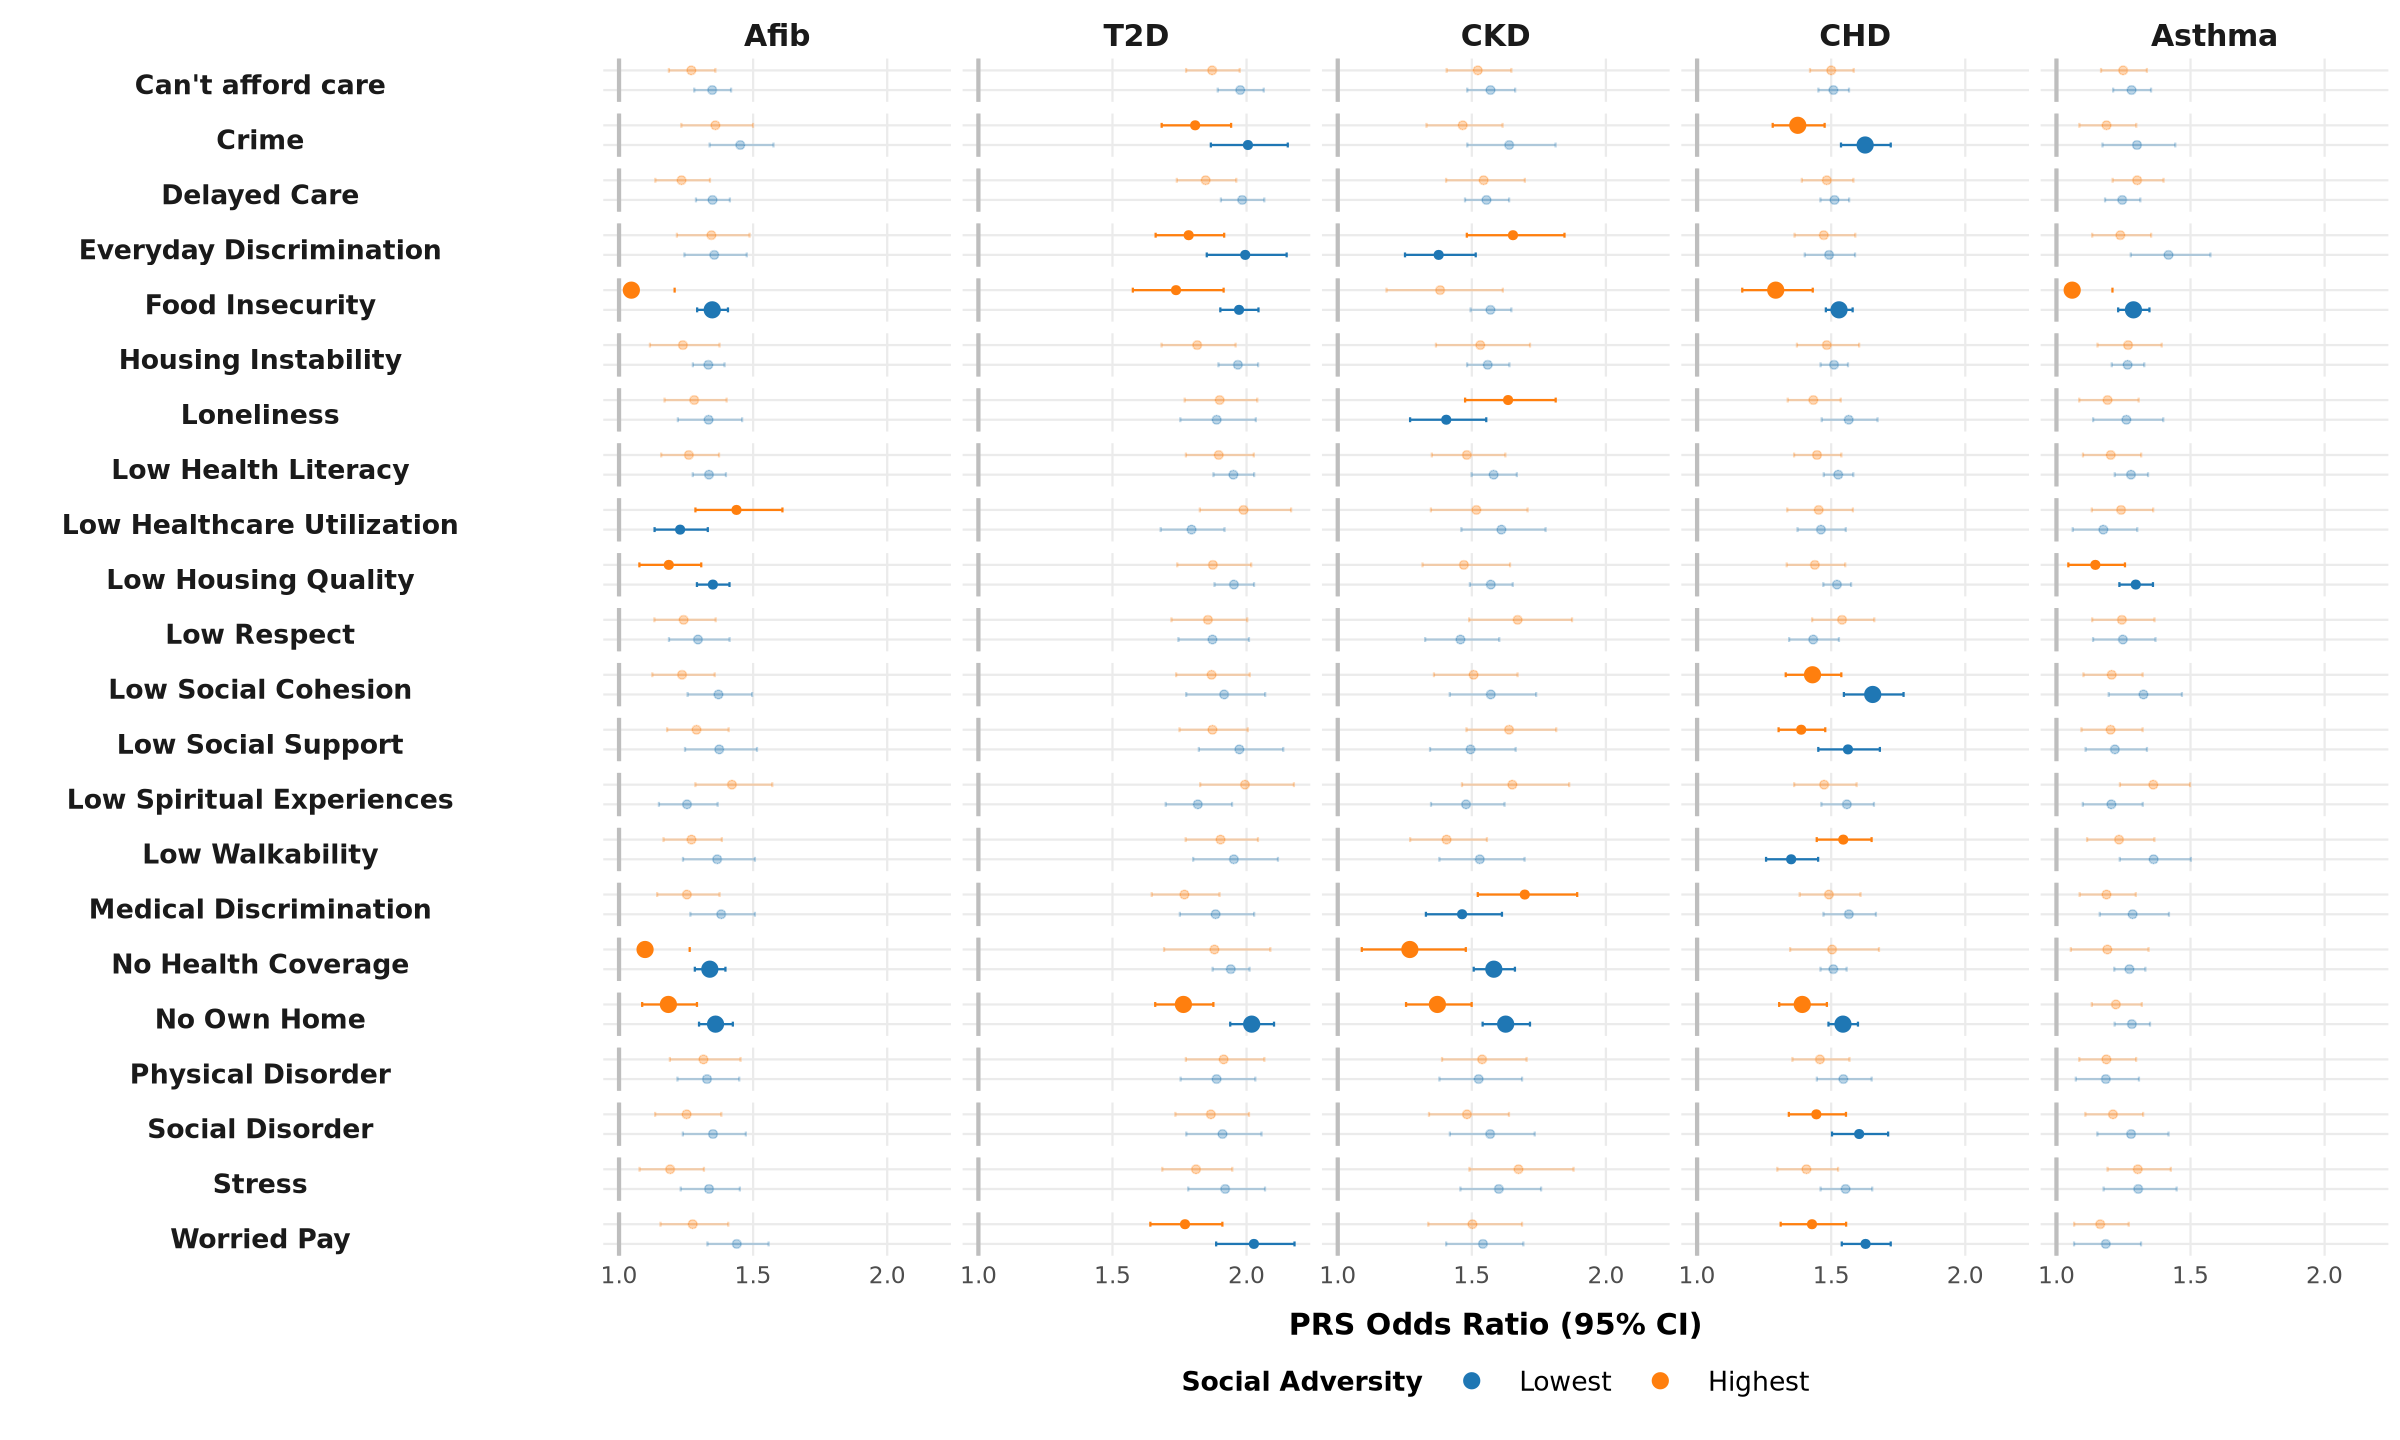

In [20]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency", "individual_poverty", "education")
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("adjusted_score", results$term), ] #Only interested in PRS term

#Map names for display
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results_adj_income_education <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

estimate_q15_out_adj_income_education <- prepare_sdoh_prs_forest_data(results_adj_income_education)

#Save table
write_excel_csv(estimate_q15_out_adj_income_education, file.path(output_dir, "OR_stratified_analyses_sdoh_controlling_income_education.csv"))

p_forest <- plot_sdoh_prs_forest(estimate_q15_out_adj_income_education)
print(p_forest)

# Redo Controlling for PCs, Income, and Education

Warning message:
“There were 19 warnings in `mutate()`.
The first warning was:
ℹ In argument: `quantile_results = list(fit_by_quantiles(formula, disease,
  sdoh_var, merged_data))`.
ℹ In row 3.
Caused by warning:
! glm.fit: fitted probabilities numerically 0 or 1 occurred
ℹ Run `dplyr::last_dplyr_warnings()` to see the 18 remaining warnings.”
`height` was translated to `width`.
Warning message:
“Removed 110 rows containing missing values or values outside the scale range
(`geom_vline()`).”


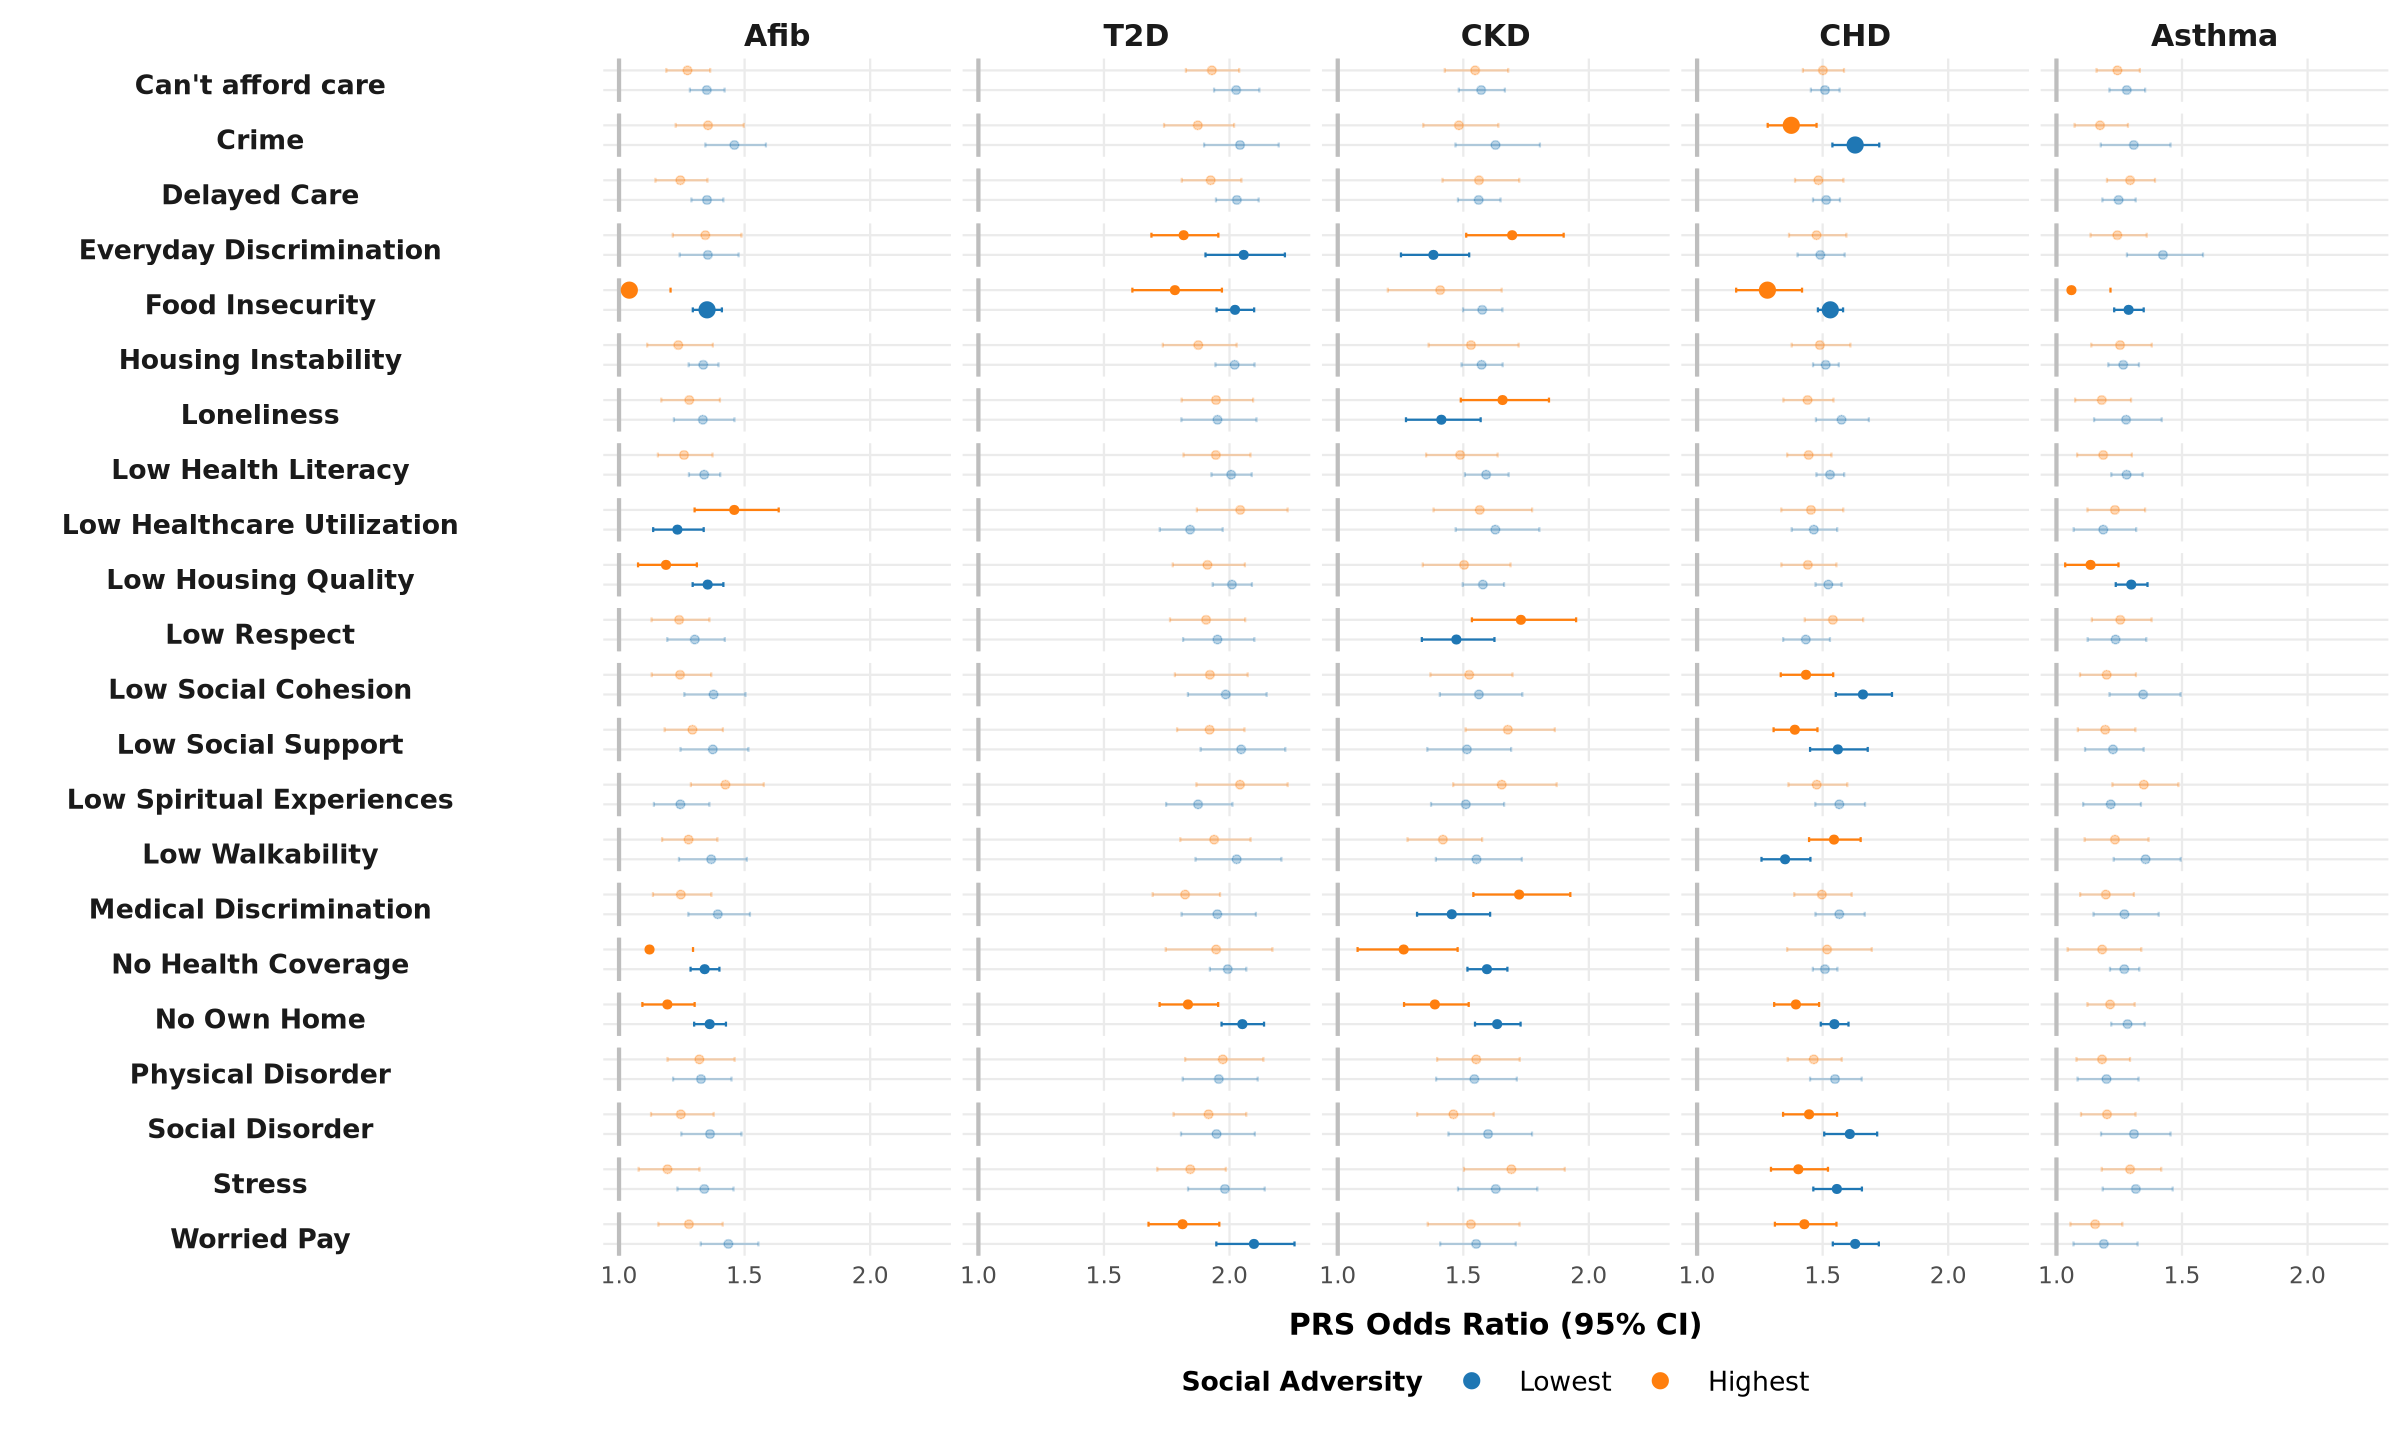

In [21]:
generate_formulas <- function(disease) {
  # Base covariates
  covariates <- c("age", "record_depth", "visit_frequency", "individual_poverty", "education",  paste0("PC_", 1:16))
  
  # All possible sex terms
  sex_terms <- c("SexGenderCis_male", "SexGenderSGM")
  
  # Disease-specific exclusions
  if (disease %in% c("CKD", "t1d")) {
    sex_terms <- setdiff(sex_terms, "SexGenderSGM")
  }
  if (disease %in% c("BreastC", "ProstateC")) {
    sex_terms <- character(0)
  }

  # Combine covariates
  base <- paste(c(covariates, sex_terms), collapse = " + ")
  score <- paste0(disease, "_adjusted_score")

  as.formula(paste(disease, "~", paste(c(base, score), collapse = " + ")))
}

# Generate combinations of diseases and SDoH variables
combinations <- expand_grid(
  disease = unlist(diseases),
  sdoh_var = sdoh_var
)

# Step 2: Generate formulas and fit models
results <- combinations %>%
  rowwise() %>%
  mutate(
    formula = list(generate_formulas(disease)),  # Generate formula for each disease
    quantile_results = list(fit_by_quantiles(formula, disease, sdoh_var, merged_data))  # Fit models by quantiles
  ) %>%
  ungroup() %>%
  select(quantile_results) %>%
  unnest(quantile_results)

#Clean up results
results<-results[results$Quantile_Group %in% c(1,5), ] #Only interested in top and bottom quantiles
results <- results[grep("adjusted_score", results$term), ] #Only interested in PRS term

#Map names for display
results$Disease <- disease_name_mapping[results$Disease]

## -----------------------------
## Recode + order factors
## -----------------------------
results_adj_both <- results %>%
    mutate(
      Disease       = factor(Disease, levels = disease_order),
      Quantile      = paste0("Q", Quantile_Group)
    ) %>%
    select(
      Disease, SDoH_Variable, Quantile_Group, Quantile,
      term, estimate, std.error, statistic, p.value,
      OR, OR_Lower, OR_Upper,
      AUC, AUC_CI_Lower, AUC_CI_Upper
    )

estimate_q15_out_adj_both <- prepare_sdoh_prs_forest_data(results_adj_both)

#Save table
write_excel_csv(estimate_q15_out_adj_both, file.path(output_dir, "OR_stratified_analyses_sdoh_controlling_income_education_PCs.csv"))

p_forest <- plot_sdoh_prs_forest(estimate_q15_out_adj_both)
print(p_forest)

# Combined Figure

In [22]:
vars_of_interest <- c("Food Insecurity", "No Own Home", "Low Walkability", "No Health Coverage")
results_no_adj_subset <- estimate_q15_out_no_adj[estimate_q15_out_no_adj$SDoH_Variable %in% vars_of_interest, ]
results_adj_PCs_subset <- estimate_q15_out_adj_PCs[estimate_q15_out_adj_PCs$SDoH_Variable %in% vars_of_interest, ]
results_adj_income_education_subset <- estimate_q15_out_adj_income_education[estimate_q15_out_adj_income_education$SDoH_Variable %in% vars_of_interest, ]
results_adj_both_subset <- estimate_q15_out_adj_both[estimate_q15_out_adj_both$SDoH_Variable %in% vars_of_interest, ]



results_no_adj_subset$adj <- "None"
results_adj_income_education_subset$adj <- "Income_education"
results_adj_PCs_subset$adj <- "PCs"
results_adj_both_subset$adj <- "both"
results_adj <- rbind(results_no_adj_subset, results_adj_income_education_subset, results_adj_PCs_subset, results_adj_both_subset)

results_adj <- results_adj |>
  dplyr::mutate(
    SDoH_Label = dplyr::case_when(

      SDoH_Variable == "No Own Home" & Quantile_Group == 1 ~ "Own Home",
      SDoH_Variable == "No Own Home" & Quantile_Group == 5 ~ "No Own Home",

      SDoH_Variable == "Food Insecurity" & Quantile_Group == 1 ~ "Food Secure",
      SDoH_Variable == "Food Insecurity" & Quantile_Group == 5 ~ "Food Insecure",

      SDoH_Variable == "Low Walkability" & Quantile_Group == 1 ~ "Walkable",
      SDoH_Variable == "Low Walkability" & Quantile_Group == 5 ~ "Low Walkability",

      SDoH_Variable == "No Health Coverage" & Quantile_Group == 1 ~ "Has Health Coverage",
      SDoH_Variable == "No Health Coverage" & Quantile_Group == 5 ~ "No Health Coverage",

      TRUE ~ SDoH_Variable
    )
  )

Warning message in geom_errorbar(..., orientation = orientation):
“Ignoring unknown aesthetics: height and show.legend”
Warning message:
“Removed 20 rows containing missing values or values outside the scale range
(`geom_vline()`).”


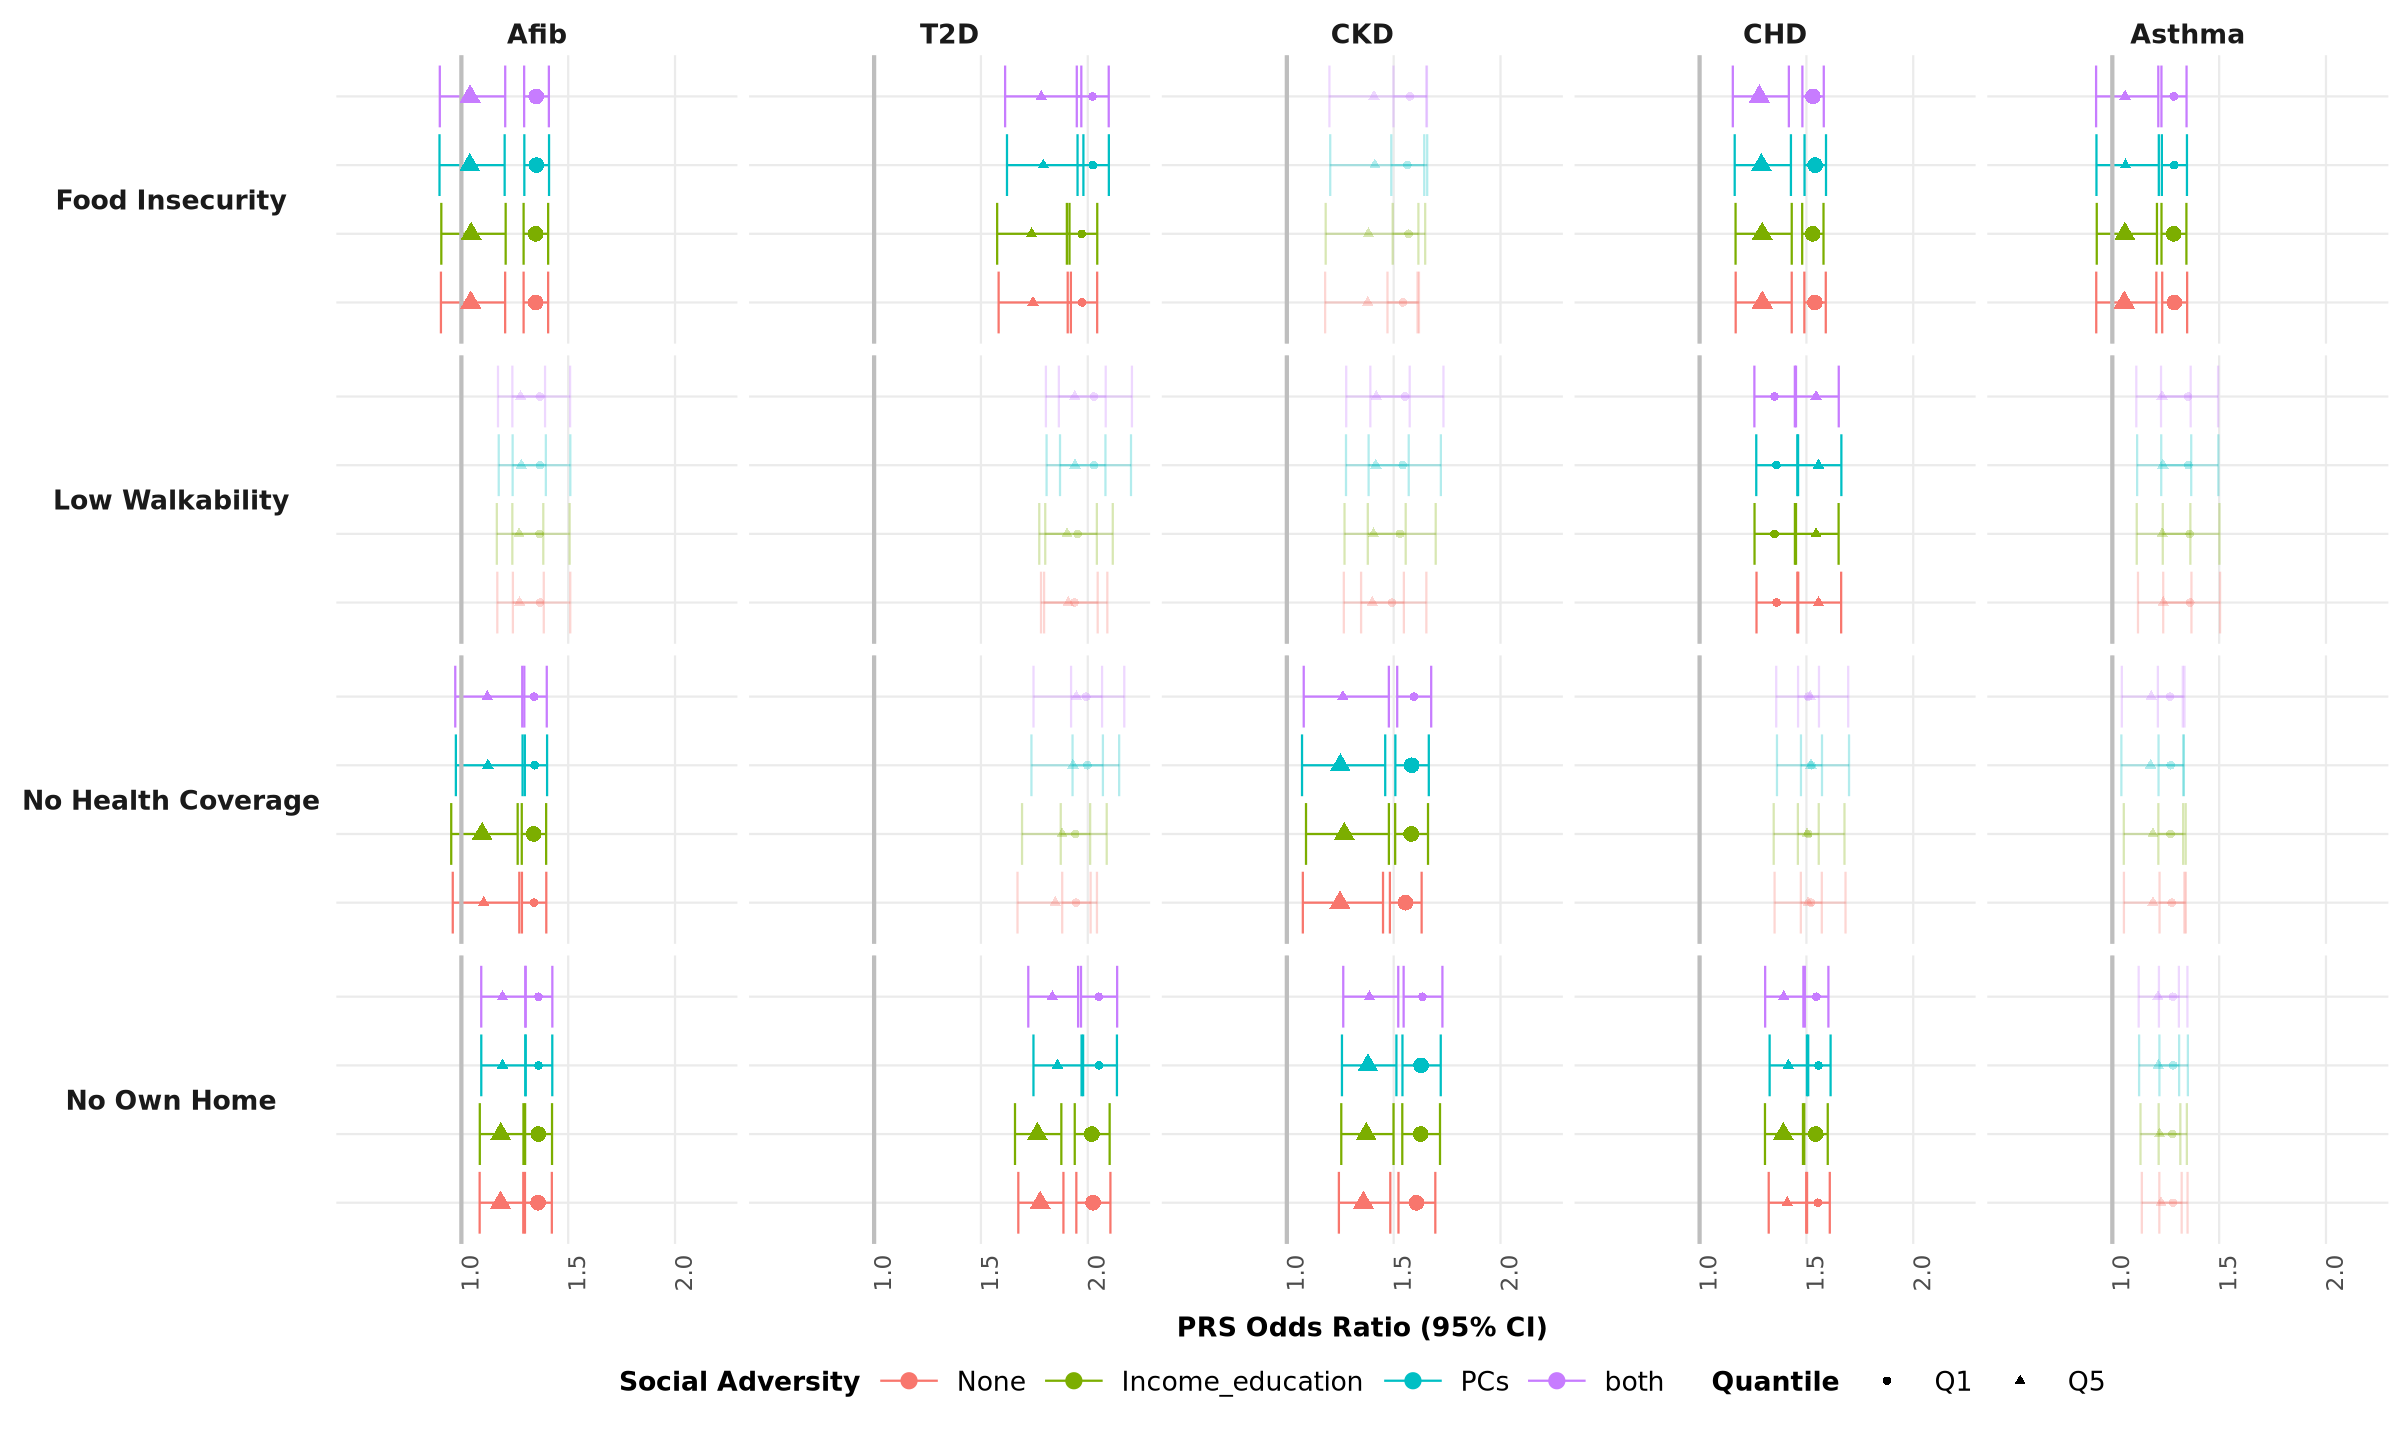

In [24]:
results_adj$adj <- factor(
  results_adj$adj,
  levels = c("None", "Income_education", "PCs", "both")
)



x_label = "PRS Odds Ratio (95% CI)"

ggplot(
    results_adj,
    aes(x = OR, y = adj, color = adj)
  ) +

    # Error bars (fade if not significant)
    geom_errorbarh(
      aes(
        xmin = OR_Lower,
        xmax = OR_Upper,
        alpha = sig,
      height = 0.25,
      show.legend = FALSE
    )) +

    # Reference lines
    geom_vline(xintercept = 0, color = "grey", linewidth = 1.2) +
    geom_vline(xintercept = 1, color = "grey", linewidth = 1.2) +

    # Points
    geom_point(
      aes(
        alpha = sig,
        size  = fdr_sig,
          shape = Quantile
      )
    ) +

    scale_x_continuous(
      name   = x_label,
      breaks = c(1, 1.5, 2),
      limits = c(
        0.5,
        max(1, max(results_adj$OR_Upper, na.rm = TRUE))
      )
    ) +

    scale_size_manual(
      values = c(`FALSE` = 2, `TRUE` = 4),
      guide  = "none"
    ) +

    scale_alpha_manual(
      values = c(`FALSE` = 0.3, `TRUE` = 1),
      guide  = "none"
    ) +

    labs(
      y     = "Quantile",
      color = "Social Adversity"
    ) +

    facet_grid(
      rows   = vars(SDoH_Variable),
      cols   = vars(Disease),
      scales = "free_y",
      switch = "y"
    ) +

    theme_minimal(base_size = 14) +
    theme(
      axis.text.x        = element_text(size = 14, margin = margin(t = 4), angle = 90),
      panel.grid.minor   = element_blank(),
      axis.title.y       = element_blank(),
      axis.title.x       = element_text(size = 16, face = "bold", margin = margin(t = 15)),
      axis.text.y        = element_blank(),
      strip.text.y.left  = element_text(size = 16, angle = 0, face = "bold", vjust = 0.5),
      strip.placement    = "outside",
      strip.text.x       = element_text(size = 16, face = "bold"),
      legend.position    = "bottom",
      legend.box.spacing = unit(-5, "pt"),
      legend.text        = element_text(size = 16),
      legend.title       = element_text(size = 16, face = "bold"),
      legend.key.size    = unit(3, "lines")
    ) +

    guides(
      color = guide_legend(override.aes = list(size = 4))
    )

In [34]:
results_heat <- results_adj %>%
  dplyr::group_by(Disease, SDoH_Variable, adj) %>%
  dplyr::summarise(
    OR_diff = OR[Quantile == "Q5"] -
              OR[Quantile == "Q1"],
       z_test_p_value = first(z_test_p_value),
    fdr_sig = first(fdr_sig),
    .groups = "drop"
  ) |> distinct()

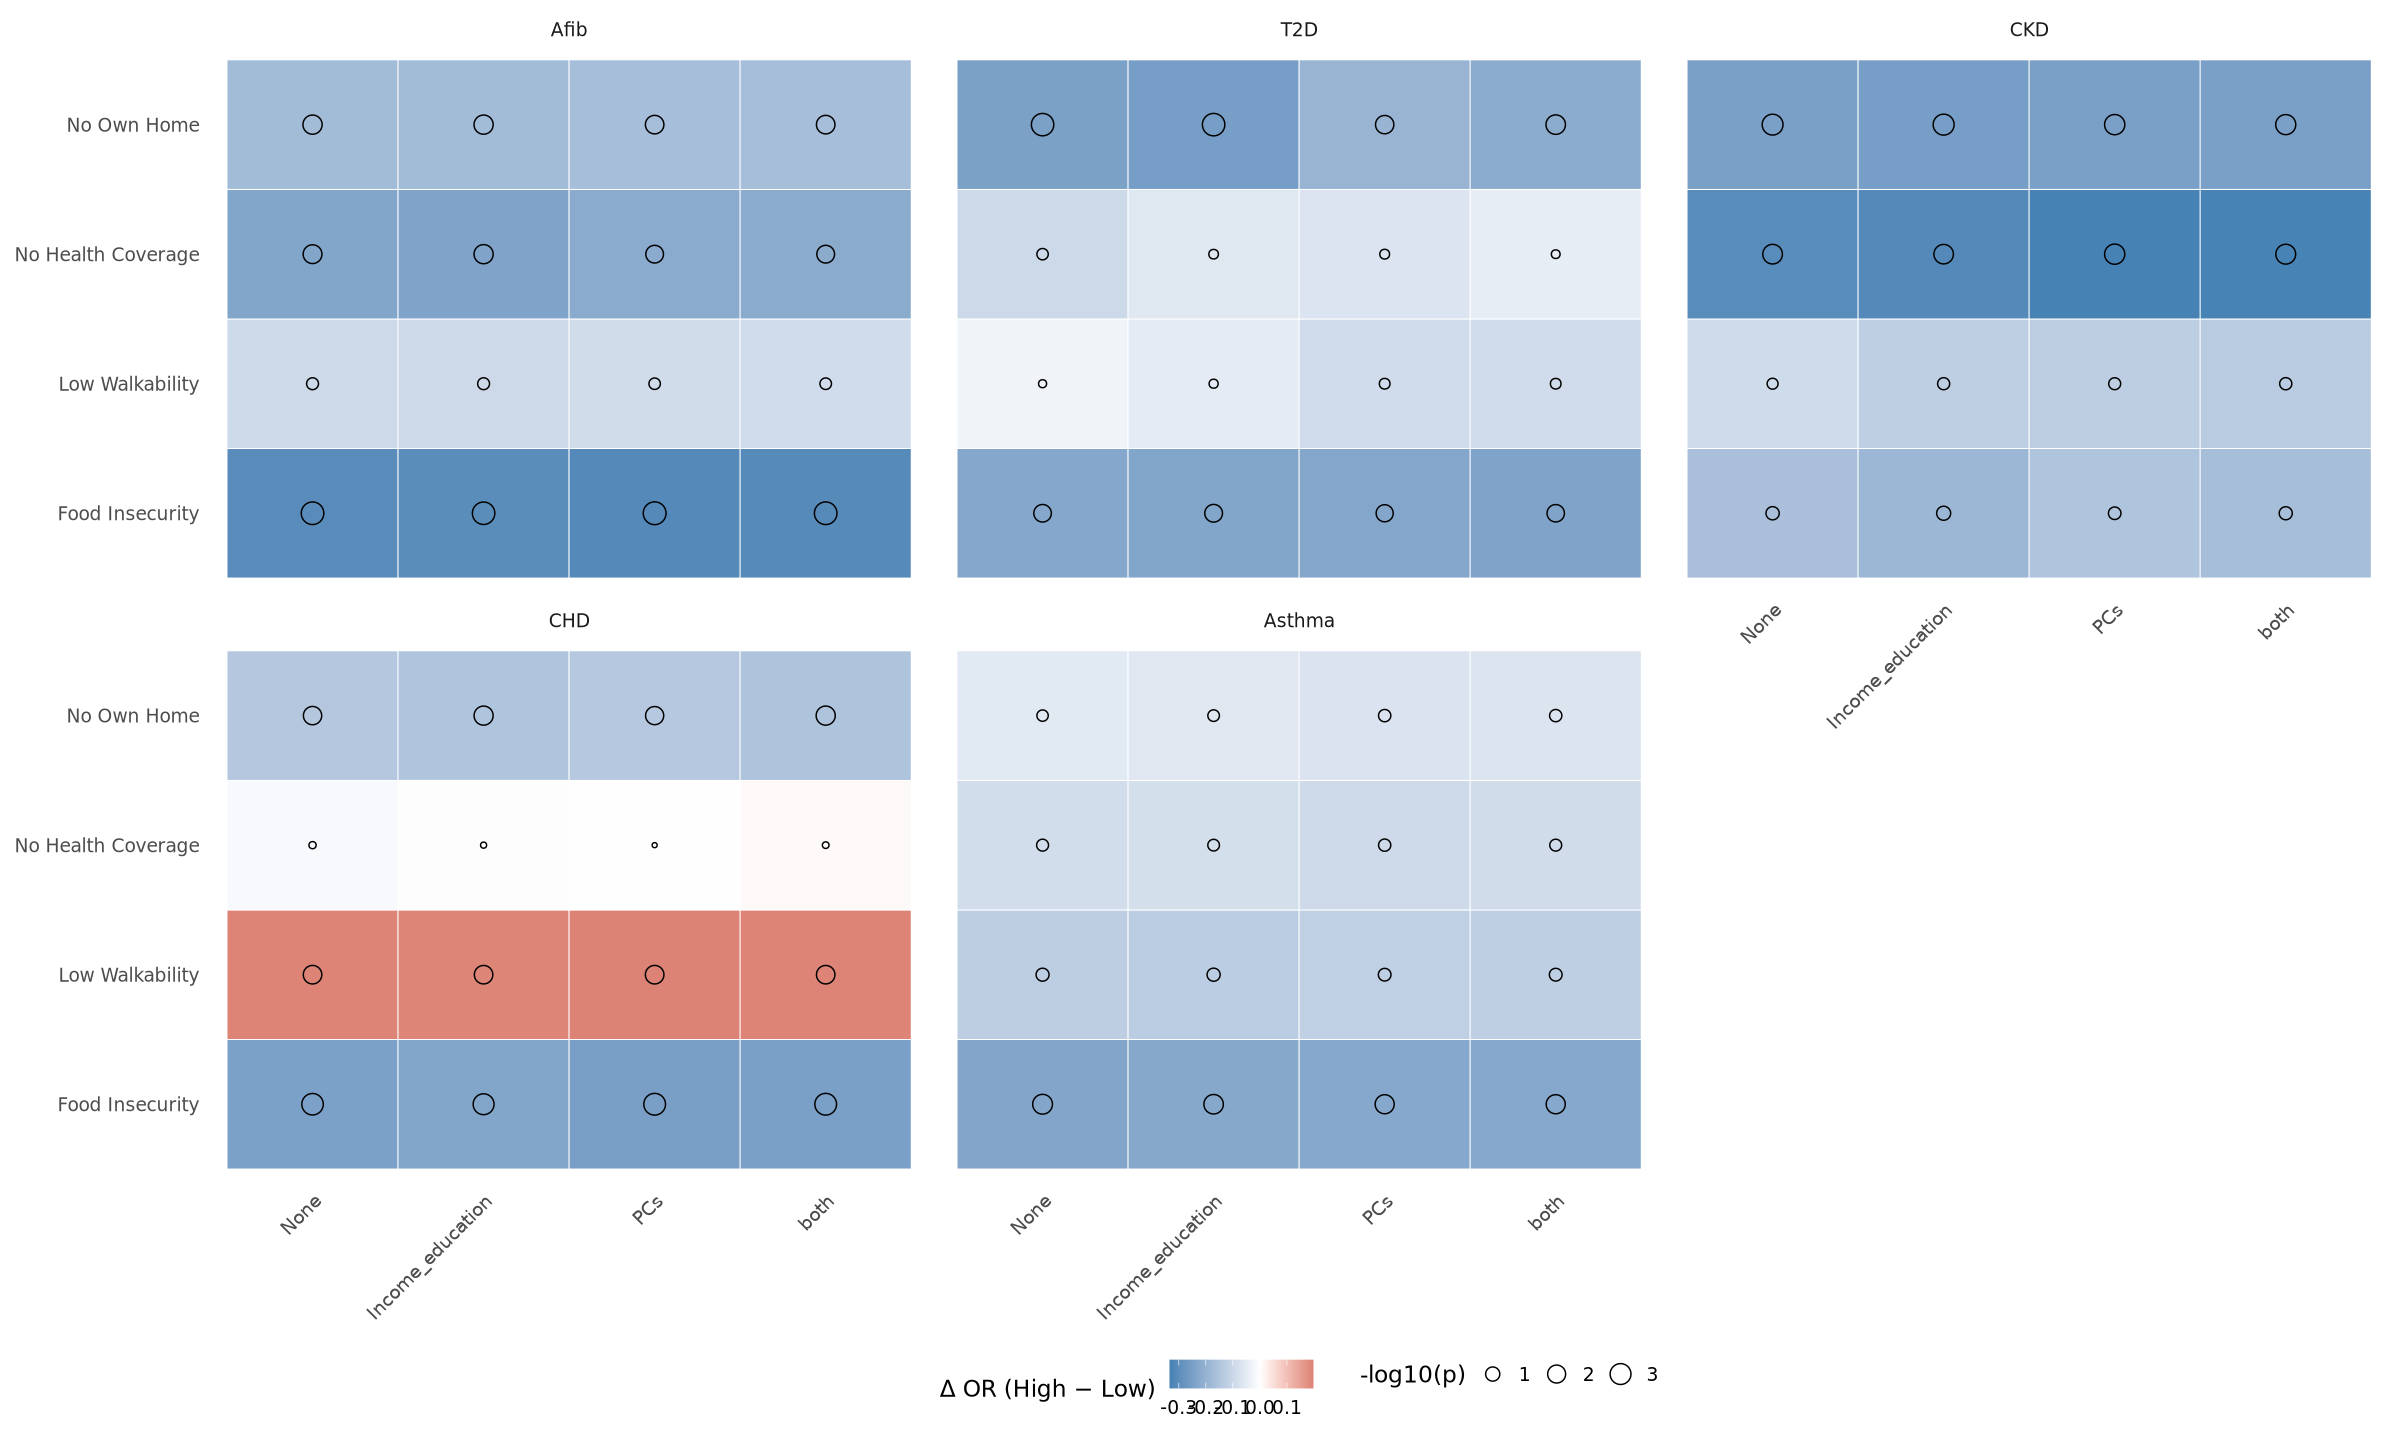

In [35]:
ggplot(results_heat, aes(
  x = adj,
  y = SDoH_Variable,
  fill = OR_diff
)) +

  geom_tile(color = "white") +

  geom_point(
    aes(size = -log10(z_test_p_value)),
    shape = 21,
    color = "black",
    fill = NA
  ) +

  facet_wrap(~ Disease) +

  scale_fill_gradient2(
    low = "steelblue",
    mid = "white",
    high = "firebrick",
    midpoint = 0,
    name = "Δ OR (High − Low)"
  ) +

  scale_size_continuous(
    name = "-log10(p)",
    range = c(1, 6)
  ) +

  theme_minimal(base_size = 14) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.title = element_blank(),
    panel.grid = element_blank(),
    legend.position = "bottom"
  )

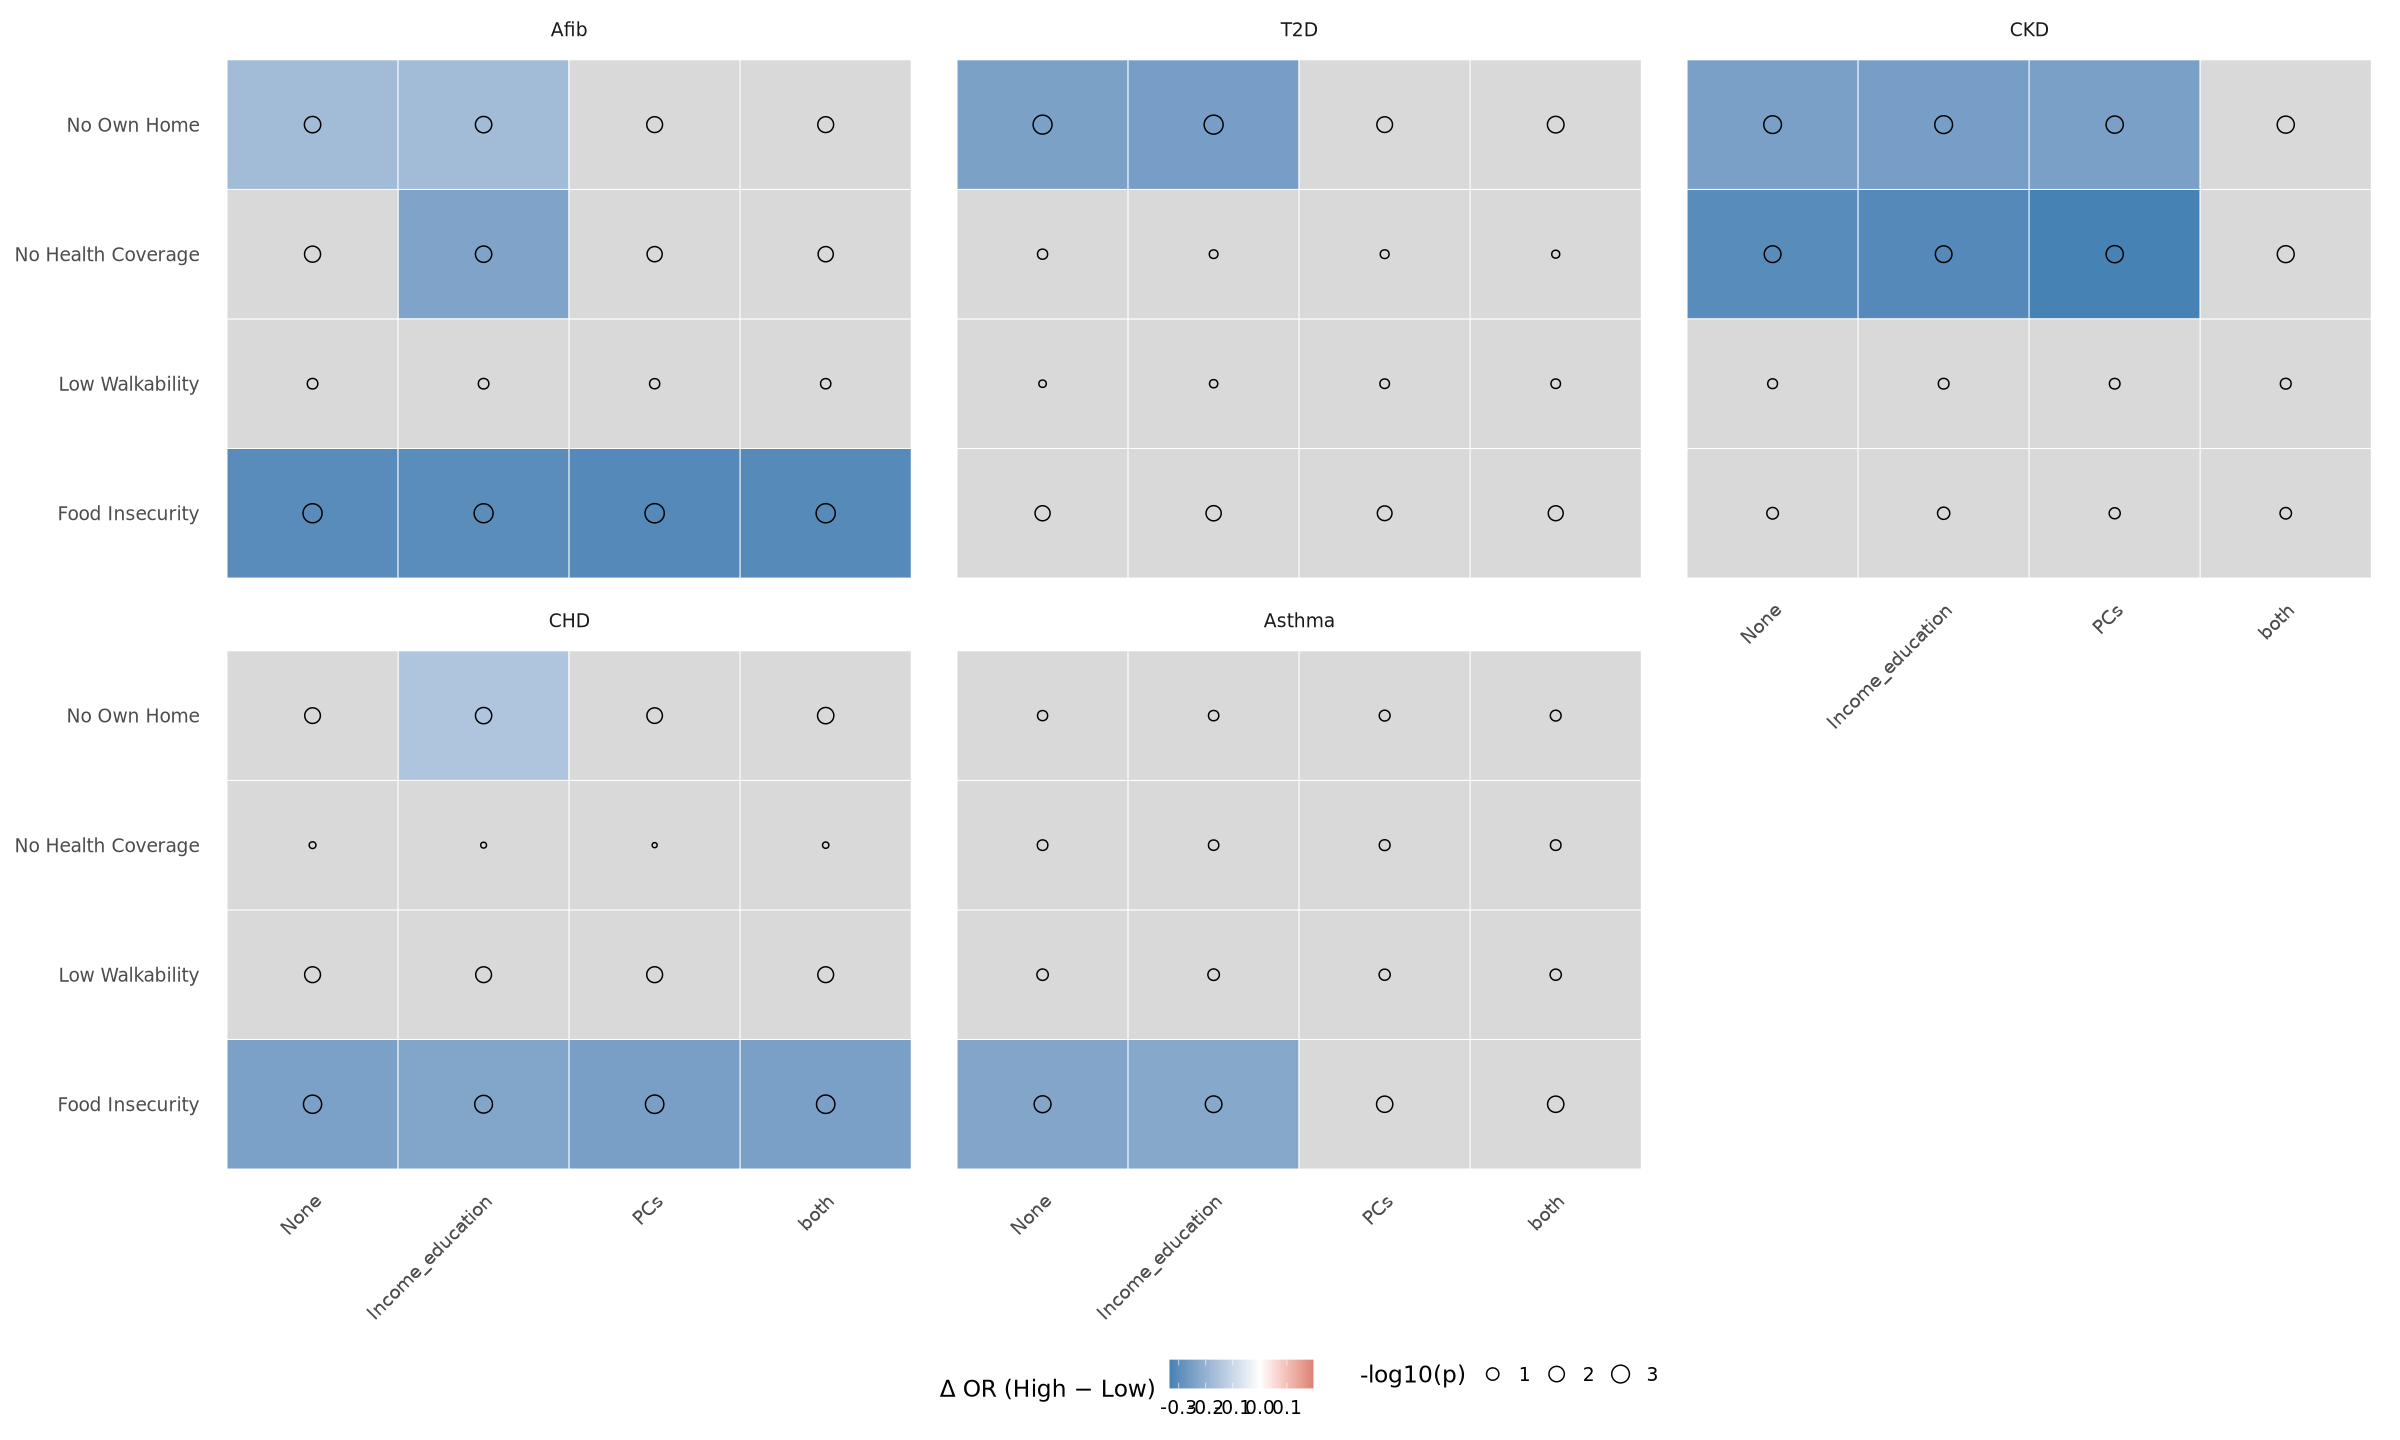

In [36]:
ggplot(results_heat, aes(
  x = adj,
  y = SDoH_Variable,
  fill = OR_diff
)) +

  # main heatmap
  geom_tile(color = "white") +

  # GREY OVERLAY for non-significant
  geom_tile(
    data = subset(results_heat, !fdr_sig),
    fill = "grey85",
    color = "white"
  ) +

  # significance dots (optional but helpful)
  geom_point(
    aes(size = -log10(z_test_p_value)),
    shape = 21,
    color = "black",
    fill = NA
  ) +

  facet_wrap(~ Disease) +

  scale_fill_gradient2(
    low = "steelblue",
    mid = "white",
    high = "firebrick",
    midpoint = 0,
    name = "Δ OR (High − Low)"
  ) +

  scale_size_continuous(
    name = "-log10(p)",
    range = c(1, 5)
  ) +

  theme_minimal(base_size = 14) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.title = element_blank(),
    panel.grid = element_blank(),
    legend.position = "bottom"
  )